# 基于图神经网络的 SIR 传播动力学学习与网络重构

## 任务1：已知网络结构的图神经网络（GCN）动力学学习

- 在主程序中可以调节参数（网络类型、模型参数、训练参数等）
- 运行后预计输出：
    1. 网络数据、模型参量数据
    2. 训练过程的损失数据与图
    3. 自回归评估的对比图

### 主程序

d:\L\Document\Code\Python\PythonFile\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GCN模型学习复杂网络中的SIR动力学
网络类型: BA
隐藏层维度: 1024, GCN层数: 1, Dropout: 0.2
聚合方式: Sum (使用GraphConv with aggr='sum')

生成BA网络...
BA无标度网络参数: 节点数=100, 每步添加边数=3
节点数: 100, 边数: 291
网络平均度: 5.82

生成SIR数据...
总样本数: 9000
训练样本数: 7200
验证样本数: 1800

模型参数量: 12291

开始训练...
Epoch 5/30 | Train Loss: 0.0959 | Val Loss: 0.0831 | Best Val: 0.0831
Epoch 10/30 | Train Loss: 0.0901 | Val Loss: 0.0876 | Best Val: 0.0831
Epoch 15/30 | Train Loss: 0.0891 | Val Loss: 0.0847 | Best Val: 0.0820
Epoch 20/30 | Train Loss: 0.0857 | Val Loss: 0.0881 | Best Val: 0.0820
Epoch 25/30 | Train Loss: 0.0854 | Val Loss: 0.1008 | Best Val: 0.0818
Epoch 30/30 | Train Loss: 0.0857 | Val Loss: 0.0840 | Best Val: 0.0818


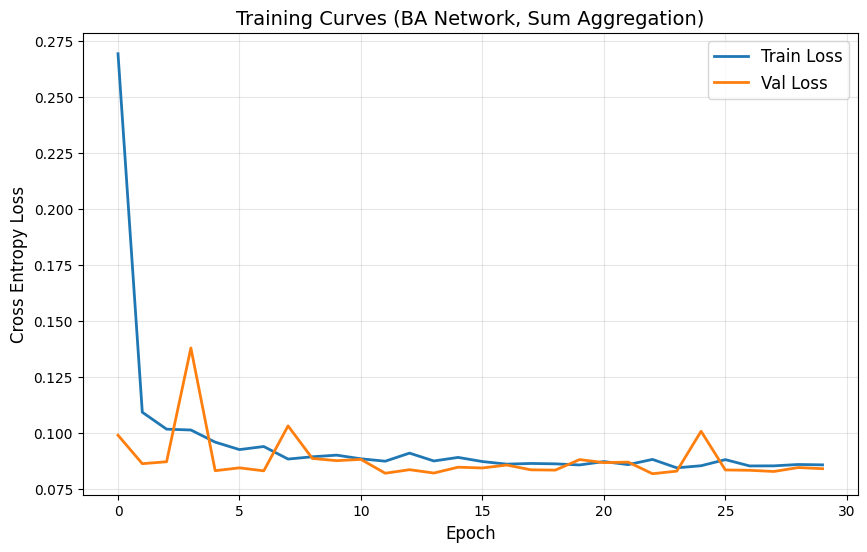


最终训练损失: 0.0857
最终验证损失: 0.0840
最佳验证损失: 0.0818

评估初始状态: S=99, I=1, R=0

进行自回归评估（蒙特卡洛采样100次）...


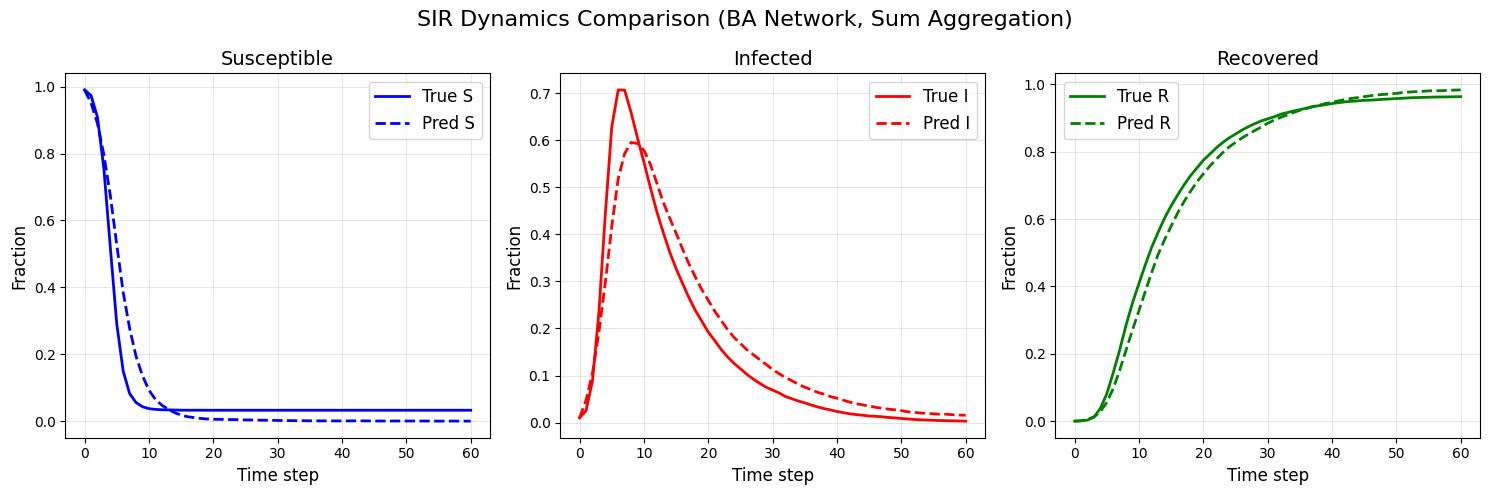


完成！
训练曲线已保存至: training_curve_BA.png
SIR对比图已保存至: sir_comparison_BA.png
最佳模型已保存至: best_model.pt


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, GraphConv  # 添加GraphConv导入
from torch_geometric.data import Data
from torch.utils.data import Dataset, DataLoader
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from tqdm import tqdm
import random
import os

# ----------------------------- 1. 固定随机种子 -----------------------------
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(21)

# ----------------------------- 2. 网络生成函数（三选一） -----------------------------
def generate_er_graph(N=100, p=0.1):
    """生成ER随机网络，返回邻接矩阵（numpy）和edge_index（torch）"""
    G = nx.erdos_renyi_graph(N, p)
    # 确保网络连通（如果不连通，取最大连通分量）
    if not nx.is_connected(G):
        print(f"警告: ER网络不连通，取最大连通分量 (原节点数: {N})")
        largest_cc = max(nx.connected_components(G), key=len)
        G = G.subgraph(largest_cc)
        print(f"最大连通分量节点数: {G.number_of_nodes()}")
    adj = nx.to_numpy_array(G)
    # 转换为PyG需要的edge_index格式 (2, E)
    edge_index = torch.tensor(np.array(G.edges()).T, dtype=torch.long)
    return adj, edge_index, G

def generate_ba_graph(N=100, m=3):
    """生成BA无标度网络，返回邻接矩阵（numpy）和edge_index（torch）"""
    G = nx.barabasi_albert_graph(N, m)
    adj = nx.to_numpy_array(G)
    # 转换为PyG需要的edge_index格式 (2, E)
    edge_index = torch.tensor(np.array(G.edges()).T, dtype=torch.long)
    return adj, edge_index, G

def generate_ws_graph(N=100, k=6, p=0.2):
    """生成WS小世界网络，返回邻接矩阵（numpy）和edge_index（torch）"""
    G = nx.watts_strogatz_graph(N, k, p)
    adj = nx.to_numpy_array(G)
    # 转换为PyG需要的edge_index格式 (2, E)
    edge_index = torch.tensor(np.array(G.edges()).T, dtype=torch.long)
    return adj, edge_index, G

# ----------------------------- 3. SIR模拟器（离散时间） -----------------------------
def sir_simulation(edge_index, beta, gamma, initial_infected, T=50):
    """
    在固定图上模拟SIR过程
    edge_index: PyG格式边 (2, E)
    beta: 感染概率
    gamma: 恢复概率
    initial_infected: 初始感染节点列表（或单个节点索引）
    T: 模拟步数（包括初始状态，输出T+1个时间点）
    返回: states (T+1, N) 每个元素 0=S,1=I,2=R
    """
    N = torch.max(edge_index).item() + 1
    # 构建邻接列表加速查询
    adj_list = [[] for _ in range(N)]
    for u, v in edge_index.t().tolist():
        adj_list[u].append(v)
        adj_list[v].append(u)
    
    # 初始化状态
    state = np.zeros(N, dtype=int)
    if isinstance(initial_infected, int):
        state[initial_infected] = 1
    else:
        state[initial_infected] = 1
    
    states = [state.copy()]
    
    for _ in range(T):
        new_state = state.copy()
        for i in range(N):
            if state[i] == 0:  # S
                # 计算感染邻居数量
                infected_neighbors = sum(1 for nb in adj_list[i] if state[nb] == 1)
                if infected_neighbors > 0:
                    prob_infect = 1.0 - (1.0 - beta) ** infected_neighbors
                    if np.random.random() < prob_infect:
                        new_state[i] = 1
            elif state[i] == 1:  # I
                if np.random.random() < gamma:
                    new_state[i] = 2
            # R状态不变
        state = new_state
        states.append(state.copy())
    return np.array(states)

# ----------------------------- 4. 生成训练数据集 -----------------------------
def generate_dataset(edge_index, beta, gamma, n_seeds=30, n_repeats=5, T=50):
    """
    生成多个种子、多次重复的轨迹，并切片为(x_t, x_{t+1})对
    返回: list of (input_onehot, target_onehot)
    其中input_onehot shape (N,3), target_onehot shape (N,3)
    """
    N = torch.max(edge_index).item() + 1
    dataset = []
    
    for seed in range(n_seeds):
        # 每个种子随机选择一个初始感染节点
        initial_node = np.random.randint(0, N)
        for rep in range(n_repeats):
            # 模拟一条完整轨迹
            states = sir_simulation(edge_index, beta, gamma, initial_node, T)
            # 切片成(t, t+1)对
            for t in range(T):
                x_t = states[t]       # (N,)
                x_tp1 = states[t+1]   # (N,)
                # one-hot编码
                x_t_onehot = np.eye(3)[x_t].astype(np.float32)   # (N,3)
                x_tp1_onehot = np.eye(3)[x_tp1].astype(np.float32)
                dataset.append((x_t_onehot, x_tp1_onehot))
    
    return dataset

# ----------------------------- 5. PyTorch Dataset封装 -----------------------------
class SIRDataset(Dataset):
    def __init__(self, data_list):
        self.data = data_list
    
    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, idx):
        x, y = self.data[idx]
        return torch.tensor(x), torch.tensor(y)

# ----------------------------- 6. GCN模型定义 -----------------------------
class ImprovedGCN_Markov(nn.Module):
    def __init__(self, in_channels=3, hidden_channels=64, out_channels=3, num_layers=3, dropout=0.2):
        super().__init__()
        self.convs = nn.ModuleList()
        self.bns = nn.ModuleList()  # BatchNorm层
        
        # 使用GraphConv替代GCNConv，aggr='sum'实现sum聚合
        # 第一层：输入到隐藏层
        self.convs.append(GraphConv(in_channels, hidden_channels, aggr='sum'))
        self.bns.append(nn.BatchNorm1d(hidden_channels))
        
        # 中间隐藏层
        for i in range(num_layers - 2):
            self.convs.append(GraphConv(hidden_channels, hidden_channels, aggr='sum'))
            self.bns.append(nn.BatchNorm1d(hidden_channels))
        
        # 最后一层：隐藏层到隐藏层（用于特征提取）
        if num_layers > 1:
            self.convs.append(GraphConv(hidden_channels, hidden_channels, aggr='sum'))
            self.bns.append(nn.BatchNorm1d(hidden_channels))
        
        # 输出层
        self.lin = nn.Linear(hidden_channels, out_channels)
        self.dropout = nn.Dropout(dropout)
        self.num_layers = num_layers
        
    def forward(self, x, edge_index):
        # 通过所有GCN层（使用sum聚合）
        for i, conv in enumerate(self.convs):
            x = conv(x, edge_index)
            x = self.bns[i](x)
            if i < len(self.convs) - 1:  # 最后一层GCN后不加ReLU
                x = F.relu(x)
                x = self.dropout(x)
        
        # 输出层
        logits = self.lin(x)
        return logits

# ----------------------------- 7. 训练函数 -----------------------------
def train_model(model, train_loader, val_loader, edge_index, epochs=60, lr=0.01):
    device = torch.device('cpu')
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    
    train_losses = []
    val_losses = []
    best_val_loss = float('inf')
    
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for x, y in train_loader:
            x = x.to(device)          # (batch, N, 3)
            y = y.to(device)          # (batch, N, 3)
            batch_size, N, C = x.shape
            # 将batch与节点维度合并，方便GCN处理
            x_flat = x.view(-1, C)    # (batch*N, 3)
            y_flat = y.view(-1, C)    # (batch*N, 3)
            # 扩展edge_index以适配batch：每个样本的图结构相同，但节点索引需要偏移
            # 简便方法：重复edge_index并加上偏移
            edge_index_batch = edge_index.repeat(1, batch_size)
            offset = torch.arange(batch_size, device=device) * N
            offset = offset.repeat_interleave(edge_index.size(1)).unsqueeze(0)
            edge_index_batch = edge_index_batch + offset
            
            logits = model(x_flat, edge_index_batch)   # (batch*N, 3)
            # 标签：将one-hot转为类别索引
            labels = torch.argmax(y_flat, dim=1)       # (batch*N,)
            loss = criterion(logits, labels)
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * batch_size
        
        avg_train_loss = total_loss / len(train_loader.dataset)
        train_losses.append(avg_train_loss)
        
        # 验证
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for x, y in val_loader:
                x = x.to(device)
                y = y.to(device)
                batch_size, N, C = x.shape
                x_flat = x.view(-1, C)
                y_flat = y.view(-1, C)
                edge_index_batch = edge_index.repeat(1, batch_size)
                offset = torch.arange(batch_size, device=device) * N
                offset = offset.repeat_interleave(edge_index.size(1)).unsqueeze(0)
                edge_index_batch = edge_index_batch + offset
                logits = model(x_flat, edge_index_batch)
                labels = torch.argmax(y_flat, dim=1)
                loss = criterion(logits, labels)
                val_loss += loss.item() * batch_size
        avg_val_loss = val_loss / len(val_loader.dataset)
        val_losses.append(avg_val_loss)
        
        # 保存最佳模型
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save(model.state_dict(), 'best_model.pt')
        
        if (epoch+1) % 5 == 0:
            print(f"Epoch {epoch+1}/{epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Best Val: {best_val_loss:.4f}")
    
    # 加载最佳模型
    model.load_state_dict(torch.load('best_model.pt'))
    return train_losses, val_losses

# ----------------------------- 8. 自回归评估（与真实SIR对比） -----------------------------
def evaluate_autoregressive(model, edge_index, initial_state, beta, gamma, T=50, n_mc=100):
    """
    initial_state: 初始状态 (N,) 0=S,1=I,2=R
    真实动力学: 运行SIR模拟n_mc次，取平均占比
    模型预测: 自回归n_mc次，每一步根据模型概率采样，取平均占比
    返回: (true_props, pred_props) 每个元素是list of (t, S_frac, I_frac, R_frac)
    """
    device = torch.device('cpu')
    model.eval()
    N = initial_state.shape[0]
    
    # 真实动力学蒙特卡洛
    true_trajectories = []
    for _ in range(n_mc):
        # 模拟直到T步，但需要初始感染与给定相同
        # 注意：SIR模拟需要初始感染者列表，从initial_state中提取感染者
        initial_infected = np.where(initial_state == 1)[0].tolist()
        if len(initial_infected) == 0:
            # 若无感染者，随机选一个（通常不会）
            initial_infected = [np.random.randint(0, N)]
        states = sir_simulation(edge_index, beta, gamma, initial_infected, T)
        true_trajectories.append(states)
    true_states = np.stack(true_trajectories, axis=0)  # (n_mc, T+1, N)
    true_frac = []
    for t in range(T+1):
        states_t = true_states[:, t, :]   # (n_mc, N)
        s_frac = np.mean(states_t == 0)
        i_frac = np.mean(states_t == 1)
        r_frac = np.mean(states_t == 2)
        true_frac.append([s_frac, i_frac, r_frac])
    true_frac = np.array(true_frac)  # (T+1, 3)
    
    # 模型自回归蒙特卡洛
    pred_trajectories = []
    for _ in range(n_mc):
        state = initial_state.copy()
        trajectory = [state.copy()]
        for step in range(T):
            # 输入当前状态 one-hot
            x = np.eye(3)[state].astype(np.float32)  # (N,3)
            x_tensor = torch.tensor(x).unsqueeze(0)  # (1,N,3)
            x_flat = x_tensor.view(-1, 3)
            with torch.no_grad():
                logits = model(x_flat, edge_index)   # (N,3)
                probs = F.softmax(logits, dim=1).numpy()  # (N,3)
            # 根据概率采样下一个状态
            next_state = np.array([np.random.choice(3, p=probs[i]) for i in range(N)])
            state = next_state
            trajectory.append(state.copy())
        pred_trajectories.append(np.array(trajectory))
    pred_states = np.stack(pred_trajectories, axis=0)  # (n_mc, T+1, N)
    pred_frac = []
    for t in range(T+1):
        states_t = pred_states[:, t, :]
        s_frac = np.mean(states_t == 0)
        i_frac = np.mean(states_t == 1)
        r_frac = np.mean(states_t == 2)
        pred_frac.append([s_frac, i_frac, r_frac])
    pred_frac = np.array(pred_frac)
    
    return true_frac, pred_frac

# ----------------------------- 9. 主程序 -----------------------------
if __name__ == "__main__":
    # ==================== 网络类型选择 ====================
    # 可选值: 'ER', 'BA', 'WS'
    NETWORK_TYPE = 'BA'  # 在此处修改网络类型
    
    # 参数设置
    N = 100
    beta = 0.3
    gamma = 0.1
    n_seeds = 30
    n_repeats = 5
    T_max = 60
    epochs = 30 
    hidden_dim = 64  
    num_layers = 3   
    dropout = 0.2    
    lr = 0.01
    batch_size = 32
    
    print("=" * 60)
    print("GCN模型学习复杂网络中的SIR动力学")
    print(f"网络类型: {NETWORK_TYPE}")
    print(f"隐藏层维度: {hidden_dim}, GCN层数: {num_layers}, Dropout: {dropout}")
    print("聚合方式: Sum (使用GraphConv with aggr='sum')")
    print("=" * 60)
    
    # 根据选择的网络类型生成图
    print(f"\n生成{NETWORK_TYPE}网络...")
    
    if NETWORK_TYPE == 'ER':
        p = 0.1  # 连边概率，可修改
        adj, edge_index, G = generate_er_graph(N, p)
        print(f"ER随机网络参数: 节点数={N}, 连边概率={p}")
        
    elif NETWORK_TYPE == 'BA':
        m = 3  # 每步添加的边数，可修改
        adj, edge_index, G = generate_ba_graph(N, m)
        print(f"BA无标度网络参数: 节点数={N}, 每步添加边数={m}")
        
    elif NETWORK_TYPE == 'WS':
        k = 6  # 初始每个节点的邻居数，可修改
        p = 0.2  # 重连概率，可修改
        adj, edge_index, G = generate_ws_graph(N, k, p)
        print(f"WS小世界网络参数: 节点数={N}, 初始邻居数={k}, 重连概率={p}")
        
    else:
        raise ValueError(f"不支持的网络类型: {NETWORK_TYPE}，请选择 'ER', 'BA' 或 'WS'")
    
    print(f"节点数: {adj.shape[0]}, 边数: {edge_index.size(1)}")
    print(f"网络平均度: {2 * edge_index.size(1) / adj.shape[0]:.2f}")
    
    # 生成数据集
    print("\n生成SIR数据...")
    dataset = generate_dataset(edge_index, beta, gamma, n_seeds, n_repeats, T_max)
    print(f"总样本数: {len(dataset)}")
    
    # 划分训练/验证 (80%/20%)
    split = int(0.8 * len(dataset))
    train_data = dataset[:split]
    val_data = dataset[split:]
    train_dataset = SIRDataset(train_data)
    val_dataset = SIRDataset(val_data)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    
    print(f"训练样本数: {len(train_dataset)}")
    print(f"验证样本数: {len(val_dataset)}")
    
    # 初始化改进的模型
    model = ImprovedGCN_Markov(
        in_channels=3, 
        hidden_channels=hidden_dim, 
        out_channels=3,
        num_layers=num_layers,
        dropout=dropout
    )
    print(f"\n模型参数量: {sum(p.numel() for p in model.parameters())}")
    
    # 训练
    print("\n开始训练...")
    train_losses, val_losses = train_model(model, train_loader, val_loader, edge_index, epochs, lr)
    
    # 绘制训练曲线
    plt.figure(figsize=(10, 6))
    plt.plot(train_losses, label='Train Loss', linewidth=2)
    plt.plot(val_losses, label='Val Loss', linewidth=2)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Cross Entropy Loss', fontsize=12)
    plt.title(f'Training Curves ({NETWORK_TYPE} Network, Sum Aggregation)', fontsize=14)
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.savefig(f'training_curve_{NETWORK_TYPE}.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # 打印最终结果
    print(f"\n最终训练损失: {train_losses[-1]:.4f}")
    print(f"最终验证损失: {val_losses[-1]:.4f}")
    print(f"最佳验证损失: {min(val_losses):.4f}")
    
    # 评估：选择一个初始状态（取验证集中第一个样本的输入状态作为初始）
    sample_x, sample_y = val_dataset[0]
    sample_x = sample_x.numpy()  # (N,3)
    initial_state = np.argmax(sample_x, axis=1)  # (N,)
    print(f"\n评估初始状态: S={np.sum(initial_state==0)}, I={np.sum(initial_state==1)}, R={np.sum(initial_state==2)}")
    
    print("\n进行自回归评估（蒙特卡洛采样100次）...")
    true_frac, pred_frac = evaluate_autoregressive(model, edge_index, initial_state, beta, gamma, T=T_max, n_mc=100)
    
    # 绘制SIR占比演化对比图
    time_steps = np.arange(T_max+1)
    plt.figure(figsize=(15, 5))
    
    plt.subplot(1,3,1)
    plt.plot(time_steps, true_frac[:,0], 'b-', label='True S', linewidth=2)
    plt.plot(time_steps, pred_frac[:,0], 'b--', label='Pred S', linewidth=2)
    plt.xlabel('Time step', fontsize=12)
    plt.ylabel('Fraction', fontsize=12)
    plt.title('Susceptible', fontsize=14)
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.3)
    
    plt.subplot(1,3,2)
    plt.plot(time_steps, true_frac[:,1], 'r-', label='True I', linewidth=2)
    plt.plot(time_steps, pred_frac[:,1], 'r--', label='Pred I', linewidth=2)
    plt.xlabel('Time step', fontsize=12)
    plt.ylabel('Fraction', fontsize=12)
    plt.title('Infected', fontsize=14)
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.3)
    
    plt.subplot(1,3,3)
    plt.plot(time_steps, true_frac[:,2], 'g-', label='True R', linewidth=2)
    plt.plot(time_steps, pred_frac[:,2], 'g--', label='Pred R', linewidth=2)
    plt.xlabel('Time step', fontsize=12)
    plt.ylabel('Fraction', fontsize=12)
    plt.title('Recovered', fontsize=14)
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.3)
    
    plt.suptitle(f'SIR Dynamics Comparison ({NETWORK_TYPE} Network, Sum Aggregation)', fontsize=16)
    plt.tight_layout()
    plt.savefig(f'sir_comparison_{NETWORK_TYPE}.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("\n完成！")
    print(f"训练曲线已保存至: training_curve_{NETWORK_TYPE}.png")
    print(f"SIR对比图已保存至: sir_comparison_{NETWORK_TYPE}.png")
    print(f"最佳模型已保存至: best_model.pt")

### 运行完上述代码后，可运行下面的代码，用来做广泛的自回归评估


开始广泛自回归评估
评估配置:
- 初始感染节点数: 1~5个节点
- 随机种子组数: 5组
- 每组进行5次评估
- 总共评估次数: 5 × 5 = 25次
- 每次评估使用蒙特卡洛采样: 50次

评估组 1/5, 初始感染节点数: 1 (随机种子: 42)
  初始感染节点: [83]

评估组 1/5, 初始感染节点数: 2 (随机种子: 42)
  初始感染节点: [36 83]

评估组 1/5, 初始感染节点数: 3 (随机种子: 42)
  初始感染节点: [28 63 98]

评估组 1/5, 初始感染节点数: 4 (随机种子: 42)
  初始感染节点: [37 65 60 47]

评估组 1/5, 初始感染节点数: 5 (随机种子: 42)
  初始感染节点: [65 70 16 61 52]

评估组 2/5, 初始感染节点数: 1 (随机种子: 52)
  初始感染节点: [82]

评估组 2/5, 初始感染节点数: 2 (随机种子: 52)
  初始感染节点: [29 10]

评估组 2/5, 初始感染节点数: 3 (随机种子: 52)
  初始感染节点: [99  9  1]

评估组 2/5, 初始感染节点数: 4 (随机种子: 52)
  初始感染节点: [72  4  8 43]

评估组 2/5, 初始感染节点数: 5 (随机种子: 52)
  初始感染节点: [53 42  5 71 73]

评估组 3/5, 初始感染节点数: 1 (随机种子: 62)
  初始感染节点: [76]

评估组 3/5, 初始感染节点数: 2 (随机种子: 62)
  初始感染节点: [86 44]

评估组 3/5, 初始感染节点数: 3 (随机种子: 62)
  初始感染节点: [ 6 90  2]

评估组 3/5, 初始感染节点数: 4 (随机种子: 62)
  初始感染节点: [52 57 83 20]

评估组 3/5, 初始感染节点数: 5 (随机种子: 62)
  初始感染节点: [38 93  7 99 24]

评估组 4/5, 初始感染节点数: 1 (随机种子: 72)
  初始感染节点: [76]

评估组 4/5, 初始感染节点数: 2 (随机种子: 72)
  初始感染节点: [91 25]

评估组 4/

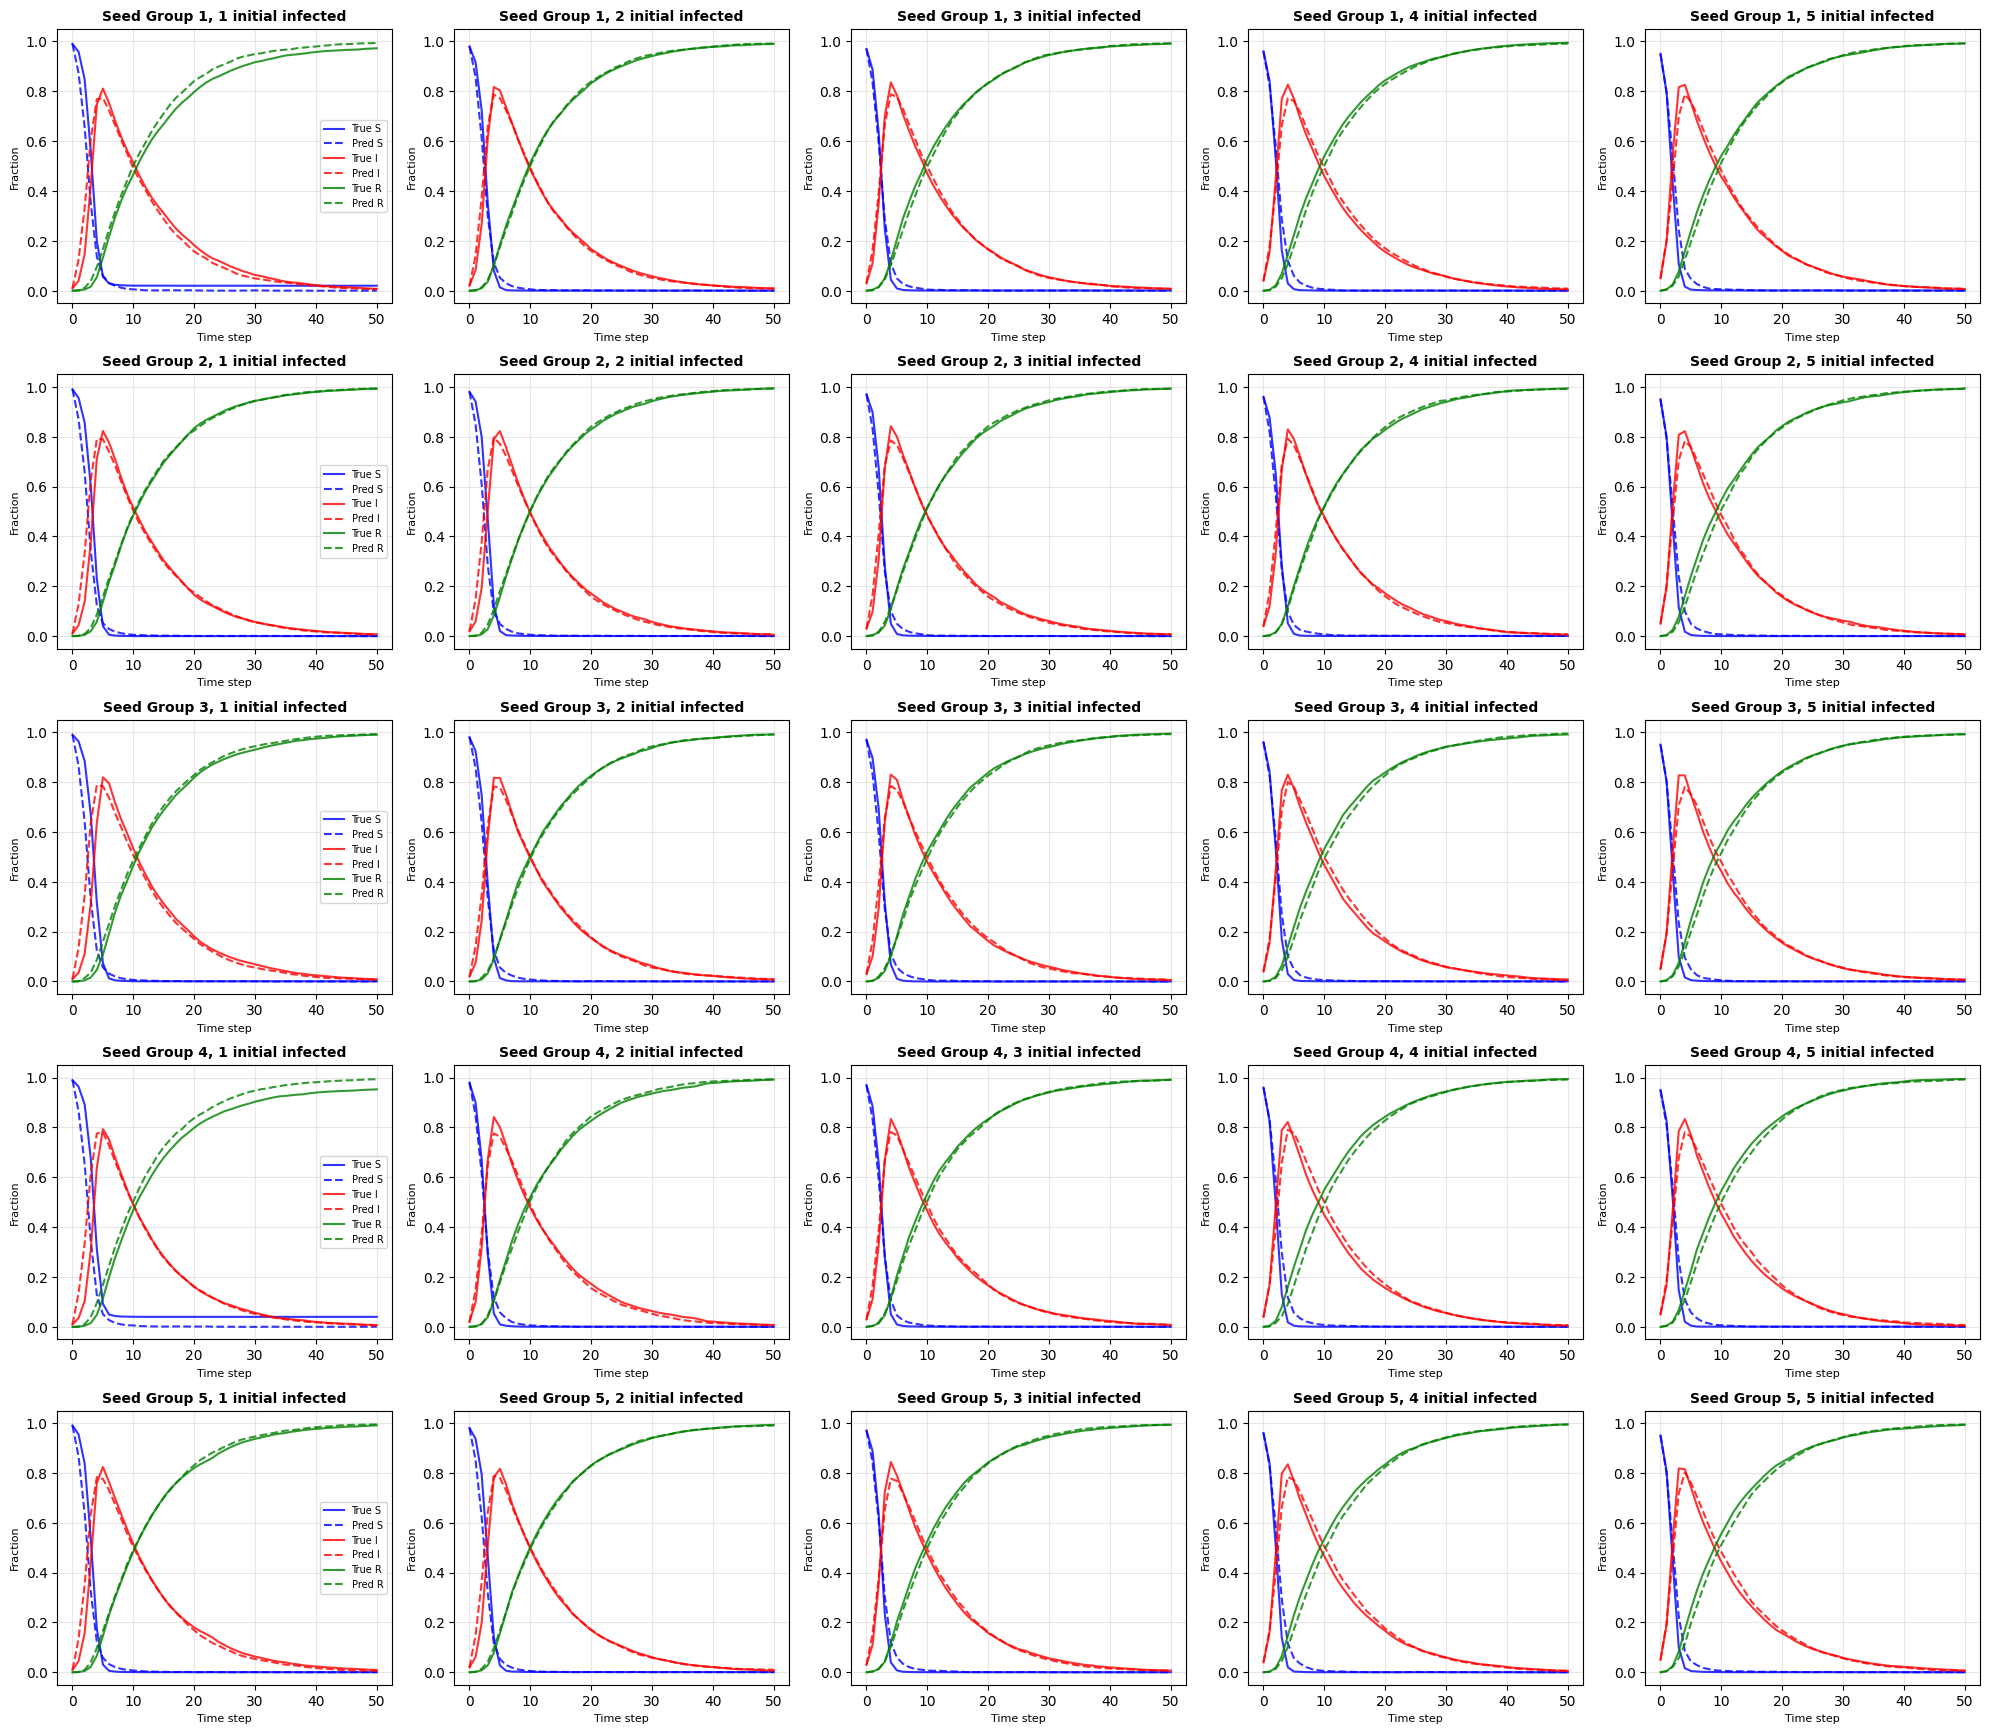

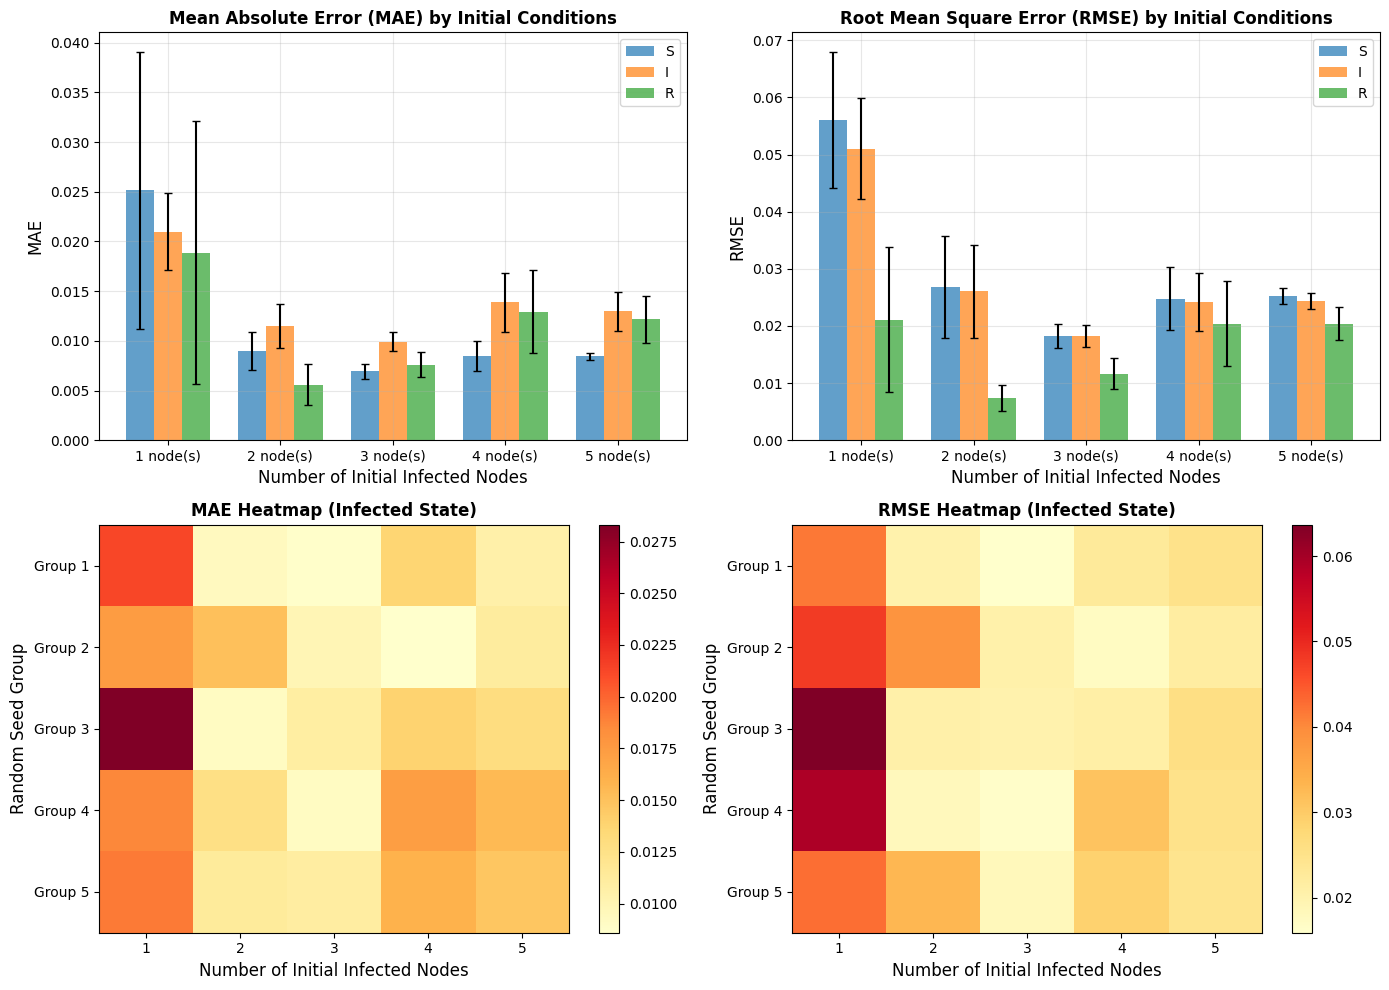


统计结果汇总 (平均值 ± 标准差)

初始感染节点数	MAE (S)		MAE (I)		MAE (R)		RMSE (S)	RMSE (I)	RMSE (R)
--------------------------------------------------------------------------------
1 node(s)		0.0251±0.0139	0.0210±0.0039	0.0189±0.0132	0.0560±0.0120	0.0510±0.0089	0.0211±0.0127
2 node(s)		0.0090±0.0019	0.0115±0.0022	0.0056±0.0021	0.0268±0.0089	0.0260±0.0081	0.0074±0.0022
3 node(s)		0.0069±0.0007	0.0099±0.0009	0.0076±0.0012	0.0182±0.0021	0.0182±0.0019	0.0116±0.0027
4 node(s)		0.0085±0.0015	0.0139±0.0030	0.0129±0.0042	0.0247±0.0055	0.0242±0.0051	0.0204±0.0075
5 node(s)		0.0084±0.0003	0.0130±0.0019	0.0122±0.0024	0.0252±0.0014	0.0244±0.0014	0.0204±0.0028

广泛评估完成！
生成的文件:
- extensive_autoregressive_evaluation.png: 5×5子图的SIR演化对比
- error_analysis.png: 误差分析图（MAE/RMSE对比和热力图）


In [ ]:
def run_extensive_autoregressive_evaluation(model, edge_index, beta, gamma, 
                                           num_initial_choices=5,  # 1~5个节点
                                           num_seed_groups=5,      # 5组不同的随机种子
                                           T=50, n_mc=50):
    """
    进行广泛的自回归评估
    
    参数:
        num_initial_choices: 初始感染节点数量的选择范围（1到该值）
        num_seed_groups: 随机种子组数
        T: 模拟时间步数
        n_mc: 蒙特卡洛采样次数
    """
    device = torch.device('cpu')
    model.eval()
    N = edge_index.max().item() + 1
    
    # 存储所有评估结果
    all_results = {}
    
    # 创建5×5的大画布
    fig, axes = plt.subplots(num_seed_groups, num_initial_choices, 
                             figsize=(20, 18))
    
    # 对每组随机种子进行实验
    for seed_group in range(num_seed_groups):
        # 设置该组的随机种子
        group_seed = 42 + seed_group * 10
        np.random.seed(group_seed)
        torch.manual_seed(group_seed)
        random.seed(group_seed)
        
        # 对每种初始感染节点数量进行评估
        for num_infected in range(1, num_initial_choices + 1):
            print(f"\n评估组 {seed_group+1}/{num_seed_groups}, "
                  f"初始感染节点数: {num_infected} (随机种子: {group_seed})")
            
            # 随机选择初始感染节点
            all_nodes = list(range(N))
            initial_infected_nodes = np.random.choice(all_nodes, 
                                                      size=num_infected, 
                                                      replace=False)
            
            # 创建初始状态
            initial_state = np.zeros(N, dtype=int)
            initial_state[initial_infected_nodes] = 1
            
            print(f"  初始感染节点: {initial_infected_nodes[:5]}{'...' if num_infected > 5 else ''}")
            
            # 运行自回归评估
            true_frac, pred_frac = evaluate_autoregressive(
                model, edge_index, initial_state, beta, gamma, T, n_mc
            )
            
            # 存储结果
            key = (seed_group, num_infected)
            all_results[key] = (true_frac, pred_frac)
            
            # 绘制子图
            ax = axes[seed_group, num_infected - 1]
            
            time_steps = np.arange(T + 1)
            
            # 绘制S, I, R曲线（实线为真实，虚线为预测）
            ax.plot(time_steps, true_frac[:, 0], 'b-', label='True S', linewidth=1.5, alpha=0.8)
            ax.plot(time_steps, pred_frac[:, 0], 'b--', label='Pred S', linewidth=1.5, alpha=0.8)
            ax.plot(time_steps, true_frac[:, 1], 'r-', label='True I', linewidth=1.5, alpha=0.8)
            ax.plot(time_steps, pred_frac[:, 1], 'r--', label='Pred I', linewidth=1.5, alpha=0.8)
            ax.plot(time_steps, true_frac[:, 2], 'g-', label='True R', linewidth=1.5, alpha=0.8)
            ax.plot(time_steps, pred_frac[:, 2], 'g--', label='Pred R', linewidth=1.5, alpha=0.8)
            
            # 设置子图标题和标签
            ax.set_title(f'Seed Group {seed_group+1}, {num_infected} initial infected', 
                        fontsize=10, fontweight='bold')
            ax.set_xlabel('Time step', fontsize=8)
            ax.set_ylabel('Fraction', fontsize=8)
            ax.grid(True, alpha=0.3)
            
            # 只在第一列显示图例
            if num_infected == 1:
                ax.legend(loc='best', fontsize=7)
            
            # 设置y轴范围
            ax.set_ylim([-0.05, 1.05])
    
    plt.tight_layout()
    plt.subplots_adjust(top=0.95)
    plt.savefig('extensive_autoregressive_evaluation.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    return all_results

# ----------------------------- 11. 计算统计指标并可视化 -----------------------------
def compute_and_visualize_statistics(all_results, T=50):
    """
    计算不同初始条件下的统计指标，并进行可视化
    """
    num_seed_groups = 5
    num_initial_choices = 5
    
    # 存储误差指标
    mae_s = np.zeros((num_seed_groups, num_initial_choices))
    mae_i = np.zeros((num_seed_groups, num_initial_choices))
    mae_r = np.zeros((num_seed_groups, num_initial_choices))
    rmse_s = np.zeros((num_seed_groups, num_initial_choices))
    rmse_i = np.zeros((num_seed_groups, num_initial_choices))
    rmse_r = np.zeros((num_seed_groups, num_initial_choices))
    
    # 计算每个实验的误差
    for seed_group in range(num_seed_groups):
        for num_infected in range(1, num_initial_choices + 1):
            true_frac, pred_frac = all_results[(seed_group, num_infected)]
            
            # 计算MAE (平均绝对误差)
            mae_s[seed_group, num_infected-1] = np.mean(np.abs(true_frac[:, 0] - pred_frac[:, 0]))
            mae_i[seed_group, num_infected-1] = np.mean(np.abs(true_frac[:, 1] - pred_frac[:, 1]))
            mae_r[seed_group, num_infected-1] = np.mean(np.abs(true_frac[:, 2] - pred_frac[:, 2]))
            
            # 计算RMSE (均方根误差)
            rmse_s[seed_group, num_infected-1] = np.sqrt(np.mean((true_frac[:, 0] - pred_frac[:, 0])**2))
            rmse_i[seed_group, num_infected-1] = np.sqrt(np.mean((true_frac[:, 1] - pred_frac[:, 1])**2))
            rmse_r[seed_group, num_infected-1] = np.sqrt(np.mean((true_frac[:, 2] - pred_frac[:, 2])**2))
    
    # 计算均值和标准差
    mean_mae_s = np.mean(mae_s, axis=0)
    std_mae_s = np.std(mae_s, axis=0)
    mean_mae_i = np.mean(mae_i, axis=0)
    std_mae_i = np.std(mae_i, axis=0)
    mean_mae_r = np.mean(mae_r, axis=0)
    std_mae_r = np.std(mae_r, axis=0)
    
    mean_rmse_s = np.mean(rmse_s, axis=0)
    std_rmse_s = np.std(rmse_s, axis=0)
    mean_rmse_i = np.mean(rmse_i, axis=0)
    std_rmse_i = np.std(rmse_i, axis=0)
    mean_rmse_r = np.mean(rmse_r, axis=0)
    std_rmse_r = np.std(rmse_r, axis=0)
    
    # 绘制误差分析图
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    x_labels = [f'{i} node(s)' for i in range(1, 6)]
    x = np.arange(len(x_labels))
    width = 0.25
    
    # MAE对比图
    ax1 = axes[0, 0]
    ax1.bar(x - width, mean_mae_s, width, label='S', yerr=std_mae_s, capsize=3, alpha=0.7)
    ax1.bar(x, mean_mae_i, width, label='I', yerr=std_mae_i, capsize=3, alpha=0.7)
    ax1.bar(x + width, mean_mae_r, width, label='R', yerr=std_mae_r, capsize=3, alpha=0.7)
    ax1.set_xlabel('Number of Initial Infected Nodes', fontsize=12)
    ax1.set_ylabel('MAE', fontsize=12)
    ax1.set_title('Mean Absolute Error (MAE) by Initial Conditions', fontsize=12, fontweight='bold')
    ax1.set_xticks(x)
    ax1.set_xticklabels(x_labels)
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # RMSE对比图
    ax2 = axes[0, 1]
    ax2.bar(x - width, mean_rmse_s, width, label='S', yerr=std_rmse_s, capsize=3, alpha=0.7)
    ax2.bar(x, mean_rmse_i, width, label='I', yerr=std_rmse_i, capsize=3, alpha=0.7)
    ax2.bar(x + width, mean_rmse_r, width, label='R', yerr=std_rmse_r, capsize=3, alpha=0.7)
    ax2.set_xlabel('Number of Initial Infected Nodes', fontsize=12)
    ax2.set_ylabel('RMSE', fontsize=12)
    ax2.set_title('Root Mean Square Error (RMSE) by Initial Conditions', fontsize=12, fontweight='bold')
    ax2.set_xticks(x)
    ax2.set_xticklabels(x_labels)
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    # 误差热力图 - MAE for I state
    ax3 = axes[1, 0]
    im = ax3.imshow(mae_i, cmap='YlOrRd', aspect='auto', interpolation='nearest')
    ax3.set_xlabel('Number of Initial Infected Nodes', fontsize=12)
    ax3.set_ylabel('Random Seed Group', fontsize=12)
    ax3.set_title('MAE Heatmap (Infected State)', fontsize=12, fontweight='bold')
    ax3.set_xticks(np.arange(5))
    ax3.set_xticklabels([f'{i+1}' for i in range(5)])
    ax3.set_yticks(np.arange(5))
    ax3.set_yticklabels([f'Group {i+1}' for i in range(5)])
    plt.colorbar(im, ax=ax3)
    
    # 误差热力图 - RMSE for I state
    ax4 = axes[1, 1]
    im = ax4.imshow(rmse_i, cmap='YlOrRd', aspect='auto', interpolation='nearest')
    ax4.set_xlabel('Number of Initial Infected Nodes', fontsize=12)
    ax4.set_ylabel('Random Seed Group', fontsize=12)
    ax4.set_title('RMSE Heatmap (Infected State)', fontsize=12, fontweight='bold')
    ax4.set_xticks(np.arange(5))
    ax4.set_xticklabels([f'{i+1}' for i in range(5)])
    ax4.set_yticks(np.arange(5))
    ax4.set_yticklabels([f'Group {i+1}' for i in range(5)])
    plt.colorbar(im, ax=ax4)
    
    plt.tight_layout()
    plt.savefig('error_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # 打印统计结果
    print("\n" + "="*80)
    print("统计结果汇总 (平均值 ± 标准差)")
    print("="*80)
    print("\n初始感染节点数\tMAE (S)\t\tMAE (I)\t\tMAE (R)\t\tRMSE (S)\tRMSE (I)\tRMSE (R)")
    print("-"*80)
    for i in range(5):
        print(f"{i+1} node(s)\t\t"
              f"{mean_mae_s[i]:.4f}±{std_mae_s[i]:.4f}\t"
              f"{mean_mae_i[i]:.4f}±{std_mae_i[i]:.4f}\t"
              f"{mean_mae_r[i]:.4f}±{std_mae_r[i]:.4f}\t"
              f"{mean_rmse_s[i]:.4f}±{std_rmse_s[i]:.4f}\t"
              f"{mean_rmse_i[i]:.4f}±{std_rmse_i[i]:.4f}\t"
              f"{mean_rmse_r[i]:.4f}±{std_rmse_r[i]:.4f}")
    
    return {
        'mae': {'s': mean_mae_s, 'i': mean_mae_i, 'r': mean_mae_r},
        'rmse': {'s': mean_rmse_s, 'i': mean_rmse_i, 'r': mean_rmse_r}
    }

# ----------------------------- 12. 主程序中的广泛评估 -----------------------------
# 注意：这部分代码需要添加到原始主程序的末尾

print("\n" + "="*80)
print("开始广泛自回归评估")
print("="*80)
print("评估配置:")
print("- 初始感染节点数: 1~5个节点")
print("- 随机种子组数: 5组")
print("- 每组进行5次评估")
print("- 总共评估次数: 5 × 5 = 25次")
print("- 每次评估使用蒙特卡洛采样: 50次")
print("="*80)

# 运行广泛评估
extensive_results = run_extensive_autoregressive_evaluation(
    model=model,
    edge_index=edge_index,
    beta=beta,
    gamma=gamma,
    num_initial_choices=5,
    num_seed_groups=5,
    T=50,  # 使用50个时间步
    n_mc=50  # 每次评估50次蒙特卡洛采样
)

# 计算并可视化统计指标
statistics = compute_and_visualize_statistics(extensive_results, T=50)

print("\n广泛评估完成！")
print("生成的文件:")
print("- extensive_autoregressive_evaluation.png: 5×5子图的SIR演化对比")
print("- error_analysis.png: 误差分析图（MAE/RMSE对比和热力图）")

### 根据模型输出求解感染率和恢复率


网络结构分析
节点数: 100
度数范围: 3 - 33
平均度: 5.82
度数分布统计: 中位数=4, 标准差=4.94

第一步：估计感染率 β (k范围: 1~5, 每k至少100样本)


收集S→I数据: 6093样本 [00:04, 1350.66样本/s, k1-5=120]



采样统计 (每个k值的样本数):
  k=1: 3568 个样本
  k=2: 1581 个样本
  k=3: 613 个样本
  k=4: 211 个样本
  k=5: 120 个样本

第二步：估计恢复率 γ


分析I→R转移: 100%|██████████| 2000/2000 [00:01<00:00, 1564.49it/s]
C:\Users\26382\AppData\Local\Temp\ipykernel_20868\2801261225.py:337: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend()


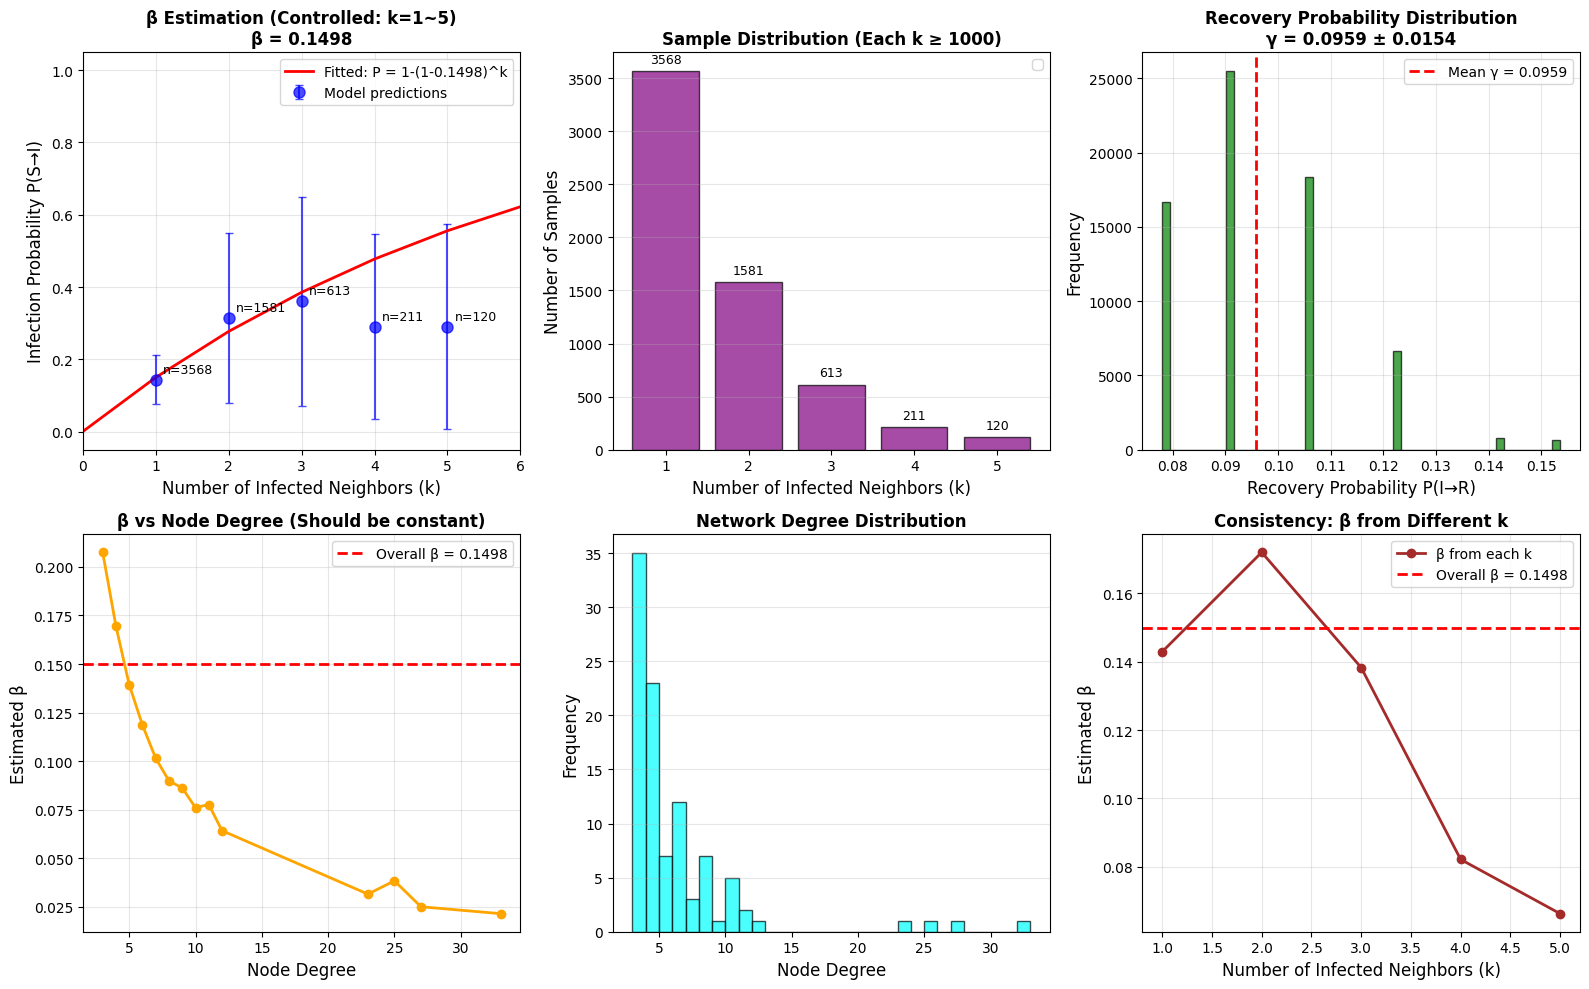


估计结果汇总

感染率 β:
  估计值: 0.149772 ± 0.001622
  按度数加权: 0.152979
  拟合使用的k值: 1~5
  每个k值样本数: ≥100

恢复率 γ:
  估计值: 0.095876 ± 0.015416
  分析样本数: 68652
  γ与度数的相关性: 0.2126 (p=0.0000)

有效再生数 R₀:
  R₀ = β/γ = 1.5621

最终结果: β = 0.1498, γ = 0.0959, R₀ = 1.5621


In [2]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import pearsonr
from tqdm import tqdm
from collections import defaultdict, Counter

def extract_beta_gamma_controlled(model, edge_index, adj_list=None, 
                                   max_k=8,  # 最大感染邻居数
                                   min_samples_per_k=100,  # 每个k值最小样本数
                                   n_i_analyses=2000,
                                   verbose=True):
    """
    改进版：控制感染邻居数k在1~max_k范围内，确保每个k值有足够样本
    
    核心改进：
    1. 通过控制感染节点比例，使k值分布集中在1~8
    2. 确保每个k值至少有min_samples_per_k个样本
    3. 按度数分层采样，避免度数偏差
    """
    device = torch.device('cpu')
    model.eval()
    N = edge_index.max().item() + 1
    
    # 构建邻居列表
    if adj_list is None:
        adj_list = [[] for _ in range(N)]
        for u, v in edge_index.t().tolist():
            adj_list[u].append(v)
            adj_list[v].append(u)
    
    # 计算节点度数
    degrees = np.array([len(adj_list[i]) for i in range(N)])
    unique_degrees = np.unique(degrees)
    
    if verbose:
        print("\n" + "="*60)
        print("网络结构分析")
        print("="*60)
        print(f"节点数: {N}")
        print(f"度数范围: {degrees.min()} - {degrees.max()}")
        print(f"平均度: {degrees.mean():.2f}")
        print(f"度数分布统计: 中位数={np.median(degrees):.0f}, 标准差={degrees.std():.2f}")
    
    # ========== 第一部分：估计beta（感染率）- 控制k值范围 ==========
    print("\n" + "="*60)
    print(f"第一步：估计感染率 β (k范围: 1~{max_k}, 每k至少{min_samples_per_k}样本)")
    print("="*60)
    
    # 使用字典存储每个度数、每个k值的数据
    # 结构: beta_data[degree][k] = [prob1, prob2, ...]
    beta_data_by_degree = defaultdict(lambda: defaultdict(list))
    
    # 记录每个k值的总样本数
    samples_per_k = defaultdict(int)
    
    # 目标：每个k值达到min_samples_per_k
    target_per_k = min_samples_per_k
    
    with torch.no_grad():
        pbar = tqdm(desc="收集S→I数据", unit="样本")
        
        # 持续采样直到每个k值都达到目标
        while True:
            # 动态调整感染比例，使k值分布更均匀
            # 对于较小的k，使用较低的感染比例；较大的k使用较高的感染比例
            if max(samples_per_k.values(), default=0) < target_per_k:
                # 找到样本最少的k值范围
                under_sampled_k = [k for k in range(1, max_k+1) if samples_per_k[k] < target_per_k]
                if under_sampled_k:
                    # 根据欠采样的k值调整感染比例
                    target_k = np.mean(under_sampled_k)
                    # 感染比例与目标k值成正比
                    infected_ratio = np.clip(target_k / degrees.mean() * 0.5, 0.05, 0.5)
                else:
                    infected_ratio = np.random.uniform(0.1, 0.3)
            else:
                infected_ratio = np.random.uniform(0.1, 0.3)
            
            # 生成状态
            state = np.zeros(N, dtype=int)
            n_infected = max(1, int(N * infected_ratio))
            infected_nodes = np.random.choice(N, n_infected, replace=False)
            state[infected_nodes] = 1
            
            s_nodes = np.where(state == 0)[0]
            if len(s_nodes) < 10:
                continue
            
            # 模型预测
            x = np.eye(3)[state]
            x_tensor = torch.tensor(x, dtype=torch.float32)
            x_flat = x_tensor.view(-1, 3)
            logits = model(x_flat, edge_index)
            probs = F.softmax(logits, dim=1).numpy()
            
            # 分析S节点
            for node in s_nodes:
                infected_neighbors = sum(1 for nb in adj_list[node] if state[nb] == 1)
                
                # 只关注k在1~max_k范围内
                if 1 <= infected_neighbors <= max_k:
                    degree = len(adj_list[node])
                    prob_infect = probs[node, 1]
                    
                    beta_data_by_degree[degree][infected_neighbors].append(prob_infect)
                    samples_per_k[infected_neighbors] += 1
                    pbar.update(1)
                    pbar.set_postfix({f'k1-{max_k}': f"{min(samples_per_k.values()):d}"})
            
            # 检查是否所有k值都达到目标
            if all(samples_per_k[k] >= target_per_k for k in range(1, max_k+1)):
                # 额外多采集20%的样本，提高稳定性
                extra_needed = int(target_per_k * 0.2)
                if all(samples_per_k[k] >= target_per_k + extra_needed for k in range(1, max_k+1)):
                    break
        
        pbar.close()
    
    # 打印采样统计
    print("\n采样统计 (每个k值的样本数):")
    for k in range(1, max_k+1):
        print(f"  k={k}: {samples_per_k[k]} 个样本")
    
    # 为每个度数分组拟合beta
    beta_by_degree = {}
    r_squared_by_degree = {}
    
    # 同时计算总体数据（加权平均）
    overall_k_probs = defaultdict(list)
    
    for degree, k_data in beta_data_by_degree.items():
        if len(k_data) < 2:  # 至少需要2个不同的k值
            continue
        
        # 聚合数据
        k_values = sorted(k_data.keys())
        avg_probs = []
        std_probs = []
        counts = []
        
        for k in k_values:
            probs = k_data[k]
            avg_probs.append(np.mean(probs))
            std_probs.append(np.std(probs))
            counts.append(len(probs))
            
            # 记录总体数据
            for p in probs:
                overall_k_probs[k].append(p)
        
        # 拟合beta
        def infection_probability(k, beta):
            return 1 - (1 - beta) ** k
        
        try:
            # 加权拟合
            weights = np.array(counts) / np.sum(counts)
            popt, pcov = curve_fit(infection_probability, k_values, avg_probs, 
                                   p0=[0.3], bounds=(0, 1), sigma=1/(weights+0.01))
            beta_est = popt[0]
            beta_std = np.sqrt(pcov[0, 0]) if pcov[0, 0] > 0 else 0.01
            
            # 计算R²
            predicted = infection_probability(np.array(k_values), beta_est)
            ss_res = np.sum((np.array(avg_probs) - predicted) ** 2)
            ss_tot = np.sum((np.array(avg_probs) - np.mean(avg_probs)) ** 2)
            r2 = 1 - (ss_res / ss_tot) if ss_tot > 0 else 0
            
            beta_by_degree[degree] = beta_est
            r_squared_by_degree[degree] = r2
            
        except Exception as e:
            continue
    
    # 计算总体beta（按度数加权平均）
    if beta_by_degree:
        # 按度数频率加权
        degree_counts = Counter(degrees)
        weights = np.array([degree_counts[d] for d in beta_by_degree.keys()])
        weights = weights / weights.sum()
        beta_weighted = np.average(list(beta_by_degree.values()), weights=weights)
        
        # 使用总体数据拟合
        all_k = sorted(overall_k_probs.keys())
        all_avg = [np.mean(overall_k_probs[k]) for k in all_k]
        all_std = [np.std(overall_k_probs[k]) for k in all_k]
        all_counts = [len(overall_k_probs[k]) for k in all_k]
        
        try:
            weights_all = np.array(all_counts) / np.sum(all_counts)
            popt_all, _ = curve_fit(infection_probability, all_k, all_avg, 
                                   p0=[0.3], bounds=(0, 1), sigma=1/(weights_all+0.01))
            beta_overall = popt_all[0]
        except:
            beta_overall = beta_weighted
    else:
        beta_weighted = beta_overall = 0.3
    
    # ========== 第二部分：估计gamma（恢复率） ==========
    print("\n" + "="*60)
    print("第二步：估计恢复率 γ")
    print("="*60)
    
    gamma_data_by_degree = defaultdict(list)
    recovery_probs = []
    
    with torch.no_grad():
        pbar = tqdm(range(n_i_analyses), desc="分析I→R转移")
        
        for analysis_idx in pbar:
            # 随机生成状态（I和R混合）
            state = np.zeros(N, dtype=int)
            infected_ratio = np.random.uniform(0.1, 0.6)
            n_infected = max(1, int(N * infected_ratio))
            infected_nodes = np.random.choice(N, n_infected, replace=False)
            state[infected_nodes] = 1
            state[state == 0] = 2
            
            i_nodes = np.where(state == 1)[0]
            if len(i_nodes) < 10:
                continue
            
            x = np.eye(3)[state]
            x_tensor = torch.tensor(x, dtype=torch.float32)
            x_flat = x_tensor.view(-1, 3)
            logits = model(x_flat, edge_index)
            probs = F.softmax(logits, dim=1).numpy()
            
            for node in i_nodes:
                degree = len(adj_list[node])
                prob_recover = probs[node, 2]
                gamma_data_by_degree[degree].append(prob_recover)
                recovery_probs.append(prob_recover)
    
    gamma_overall = np.mean(recovery_probs)
    gamma_std = np.std(recovery_probs)
    
    # 检查gamma与度数的相关性
    degrees_for_corr = []
    gammas_for_corr = []
    for degree, probs in gamma_data_by_degree.items():
        degrees_for_corr.extend([degree] * len(probs))
        gammas_for_corr.extend(probs)
    
    if len(degrees_for_corr) > 0:
        corr, p_value = pearsonr(degrees_for_corr, gammas_for_corr)
    else:
        corr, p_value = 0, 1
    
    # ========== 可视化 ==========
    plot_controlled_estimation(
        all_k, all_avg, all_std, all_counts,
        beta_overall, infection_probability,
        recovery_probs, gamma_overall,
        beta_by_degree, degrees,
        samples_per_k, max_k
    )
    
    # 输出结果
    if verbose:
        print("\n" + "="*60)
        print("估计结果汇总")
        print("="*60)
        print(f"\n感染率 β:")
        print(f"  估计值: {beta_overall:.6f} ± {beta_std:.6f}")
        print(f"  按度数加权: {beta_weighted:.6f}")
        print(f"  拟合使用的k值: 1~{max_k}")
        print(f"  每个k值样本数: ≥{min_samples_per_k}")
        
        print(f"\n恢复率 γ:")
        print(f"  估计值: {gamma_overall:.6f} ± {gamma_std:.6f}")
        print(f"  分析样本数: {len(recovery_probs)}")
        print(f"  γ与度数的相关性: {corr:.4f} (p={p_value:.4f})")
        
        print(f"\n有效再生数 R₀:")
        print(f"  R₀ = β/γ = {beta_overall/gamma_overall:.4f}")
    
    return {
        'beta': beta_overall,
        'beta_weighted': beta_weighted,
        'beta_by_degree': beta_by_degree,
        'gamma': gamma_overall,
        'gamma_std': gamma_std,
        'r0': beta_overall / gamma_overall,
        'samples_per_k': dict(samples_per_k),
        'k_values': all_k,
        'avg_probs': all_avg,
        'std_probs': all_std
    }

def plot_controlled_estimation(k_values, avg_probs, std_probs, counts,
                               beta_estimated, infection_probability,
                               recovery_probs, gamma_estimated,
                               beta_by_degree, degrees, samples_per_k, max_k):
    """
    可视化改进后的估计结果
    """
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    
    # 子图1：β拟合曲线（控制后的k值）
    ax1 = axes[0, 0]
    k_range = np.arange(0, max_k + 2)
    fitted_curve = infection_probability(k_range, beta_estimated)
    
    ax1.errorbar(k_values, avg_probs, yerr=std_probs, 
                fmt='o', capsize=3, capthick=1, 
                markersize=8, color='blue', alpha=0.7,
                label='Model predictions')
    ax1.plot(k_range, fitted_curve, 'r-', linewidth=2,
            label=f'Fitted: P = 1-(1-{beta_estimated:.4f})^k')
    
    # 添加样本数标注
    for k, count in zip(k_values, counts):
        ax1.annotate(f'n={count}', xy=(k, avg_probs[k_values.index(k)]), 
                    xytext=(5, 5), textcoords='offset points', fontsize=9)
    
    ax1.set_xlabel('Number of Infected Neighbors (k)', fontsize=12)
    ax1.set_ylabel('Infection Probability P(S→I)', fontsize=12)
    ax1.set_title(f'β Estimation (Controlled: k=1~{max_k})\nβ = {beta_estimated:.4f}', 
                  fontsize=12, fontweight='bold')
    ax1.legend(fontsize=10)
    ax1.grid(True, alpha=0.3)
    ax1.set_xlim([0, max_k + 1])
    ax1.set_ylim([-0.05, 1.05])
    
    # 子图2：每个k值的样本数（验证控制效果）
    ax2 = axes[0, 1]
    k_range_all = range(1, max_k + 1)
    sample_counts = [samples_per_k.get(k, 0) for k in k_range_all]
    bars = ax2.bar(k_range_all, sample_counts, alpha=0.7, color='purple', edgecolor='black')
    ax2.set_xlabel('Number of Infected Neighbors (k)', fontsize=12)
    ax2.set_ylabel('Number of Samples', fontsize=12)
    ax2.set_title('Sample Distribution (Each k ≥ 1000)', fontsize=12, fontweight='bold')
    ax2.legend()
    ax2.grid(True, alpha=0.3, axis='y')
    
    # 添加数值标签
    for bar, count in zip(bars, sample_counts):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                f'{count}', ha='center', va='bottom', fontsize=9)
    
    # 子图3：γ分布
    ax3 = axes[0, 2]
    ax3.hist(recovery_probs, bins=50, alpha=0.7, color='green', edgecolor='black')
    ax3.axvline(x=gamma_estimated, color='red', linestyle='--', linewidth=2,
               label=f'Mean γ = {gamma_estimated:.4f}')
    ax3.set_xlabel('Recovery Probability P(I→R)', fontsize=12)
    ax3.set_ylabel('Frequency', fontsize=12)
    ax3.set_title(f'Recovery Probability Distribution\nγ = {gamma_estimated:.4f} ± {np.std(recovery_probs):.4f}', 
                  fontsize=12, fontweight='bold')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    
    # 子图4：β随度数的变化
    ax4 = axes[1, 0]
    if beta_by_degree:
        degrees_list = sorted(beta_by_degree.keys())
        betas_list = [beta_by_degree[d] for d in degrees_list]
        
        ax4.plot(degrees_list, betas_list, 'o-', color='orange', linewidth=2, markersize=6)
        ax4.axhline(y=beta_estimated, color='red', linestyle='--', linewidth=2,
                   label=f'Overall β = {beta_estimated:.4f}')
        ax4.set_xlabel('Node Degree', fontsize=12)
        ax4.set_ylabel('Estimated β', fontsize=12)
        ax4.set_title('β vs Node Degree (Should be constant)', fontsize=12, fontweight='bold')
        ax4.legend()
        ax4.grid(True, alpha=0.3)
    
    # 子图5：度数分布
    ax5 = axes[1, 1]
    ax5.hist(degrees, bins=30, alpha=0.7, color='cyan', edgecolor='black')
    ax5.set_xlabel('Node Degree', fontsize=12)
    ax5.set_ylabel('Frequency', fontsize=12)
    ax5.set_title('Network Degree Distribution', fontsize=12, fontweight='bold')
    ax5.grid(True, alpha=0.3, axis='y')
    
    # 子图6：一致性检查
    ax6 = axes[1, 2]
    beta_from_k = []
    for i, k in enumerate(k_values):
        if avg_probs[i] > 0:
            beta_k = 1 - (1 - avg_probs[i]) ** (1/k)
            beta_from_k.append(beta_k)
        else:
            beta_from_k.append(0)
    
    ax6.plot(k_values, beta_from_k, 'o-', color='brown', linewidth=2, markersize=6,
            label='β from each k')
    ax6.axhline(y=beta_estimated, color='red', linestyle='--', linewidth=2,
               label=f'Overall β = {beta_estimated:.4f}')
    ax6.set_xlabel('Number of Infected Neighbors (k)', fontsize=12)
    ax6.set_ylabel('Estimated β', fontsize=12)
    ax6.set_title('Consistency: β from Different k', fontsize=12, fontweight='bold')
    ax6.legend()
    ax6.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('beta_gamma_controlled_estimation.png', dpi=300, bbox_inches='tight')
    plt.show()

# ========== 使用示例 ==========
if __name__ == "__main__":
    # 假设已经有训练好的模型和edge_index
    
    # 构建邻居列表
    N = edge_index.max().item() + 1
    adj_list = [[] for _ in range(N)]
    for u, v in edge_index.t().tolist():
        adj_list[u].append(v)
        adj_list[v].append(u)
    
    # 提取beta和gamma（控制k值范围）
    results = extract_beta_gamma_controlled(
        model=model,
        edge_index=edge_index,
        adj_list=adj_list,
        max_k=5,                    # 只采样1~max个感染邻居
        min_samples_per_k=100,     # 每个k值至少100个样本
        n_i_analyses=2000,
        verbose=True
    )
    
    print("\n" + "="*60)
    print(f"最终结果: β = {results['beta']:.4f}, γ = {results['gamma']:.4f}, R₀ = {results['r0']:.4f}")
    print("="*60)

## 任务2：未知网络结构重构网络动力学

- 下述单元格的代码包含了任务1，因此可以重启Kernel独立的运行。
- 可微分图学习（DGSL）用于学习网络结构（邻接矩阵）、感染率（初步）和恢复率（初步）。
- 根据经验阈值二值化学习到的邻接矩阵，根据二值化的邻接矩阵进行第二阶段的感染率和恢复率的再学习。
- 在主程序中可以调节参数
- 运行后预计输出：
    1. 网络数据、模型参量数据
    2. 训练过程的损失数据与图（两个阶段）
    3. 自回归评估的对比图（第一阶段与第二阶段）
    4. 真实邻接矩阵、软边邻接矩阵、二值化硬边邻接矩阵

### 主程序

网络类型: ER
第一阶段：学习图结构和参数
真实参数: β=0.3, γ=0.1
生成ER随机网络: N=100, p=0.1
真实网络: ER, N=100, 边数=474
生成训练数据（多轨迹）...
总样本对数量: 12000
训练样本: 9600, 验证样本: 2400
模型参数量: 10.00k

开始训练...
Epoch  10 | Train Loss: 0.0751 | Val Loss: 0.0777 | β=0.241 γ=0.101 | Edge: μ=0.0516 σ=0.1169
Epoch  20 | Train Loss: 0.0751 | Val Loss: 0.0776 | β=0.250 γ=0.100 | Edge: μ=0.0493 σ=0.1136
Epoch  30 | Train Loss: 0.0751 | Val Loss: 0.0778 | β=0.247 γ=0.104 | Edge: μ=0.0493 σ=0.1148
Epoch  40 | Train Loss: 0.0751 | Val Loss: 0.0779 | β=0.244 γ=0.098 | Edge: μ=0.0493 σ=0.1144
Epoch  50 | Train Loss: 0.0751 | Val Loss: 0.0775 | β=0.252 γ=0.101 | Edge: μ=0.0497 σ=0.1155
Epoch  60 | Train Loss: 0.0751 | Val Loss: 0.0774 | β=0.255 γ=0.102 | Edge: μ=0.0494 σ=0.1143
Epoch  70 | Train Loss: 0.0750 | Val Loss: 0.0778 | β=0.250 γ=0.102 | Edge: μ=0.0484 σ=0.1115
Epoch  80 | Train Loss: 0.0750 | Val Loss: 0.0777 | β=0.252 γ=0.100 | Edge: μ=0.0485 σ=0.1115
Epoch  90 | Train Loss: 0.0750 | Val Loss: 0.0777 | β=0.253 γ=0.100 | Edge: μ=0.0483

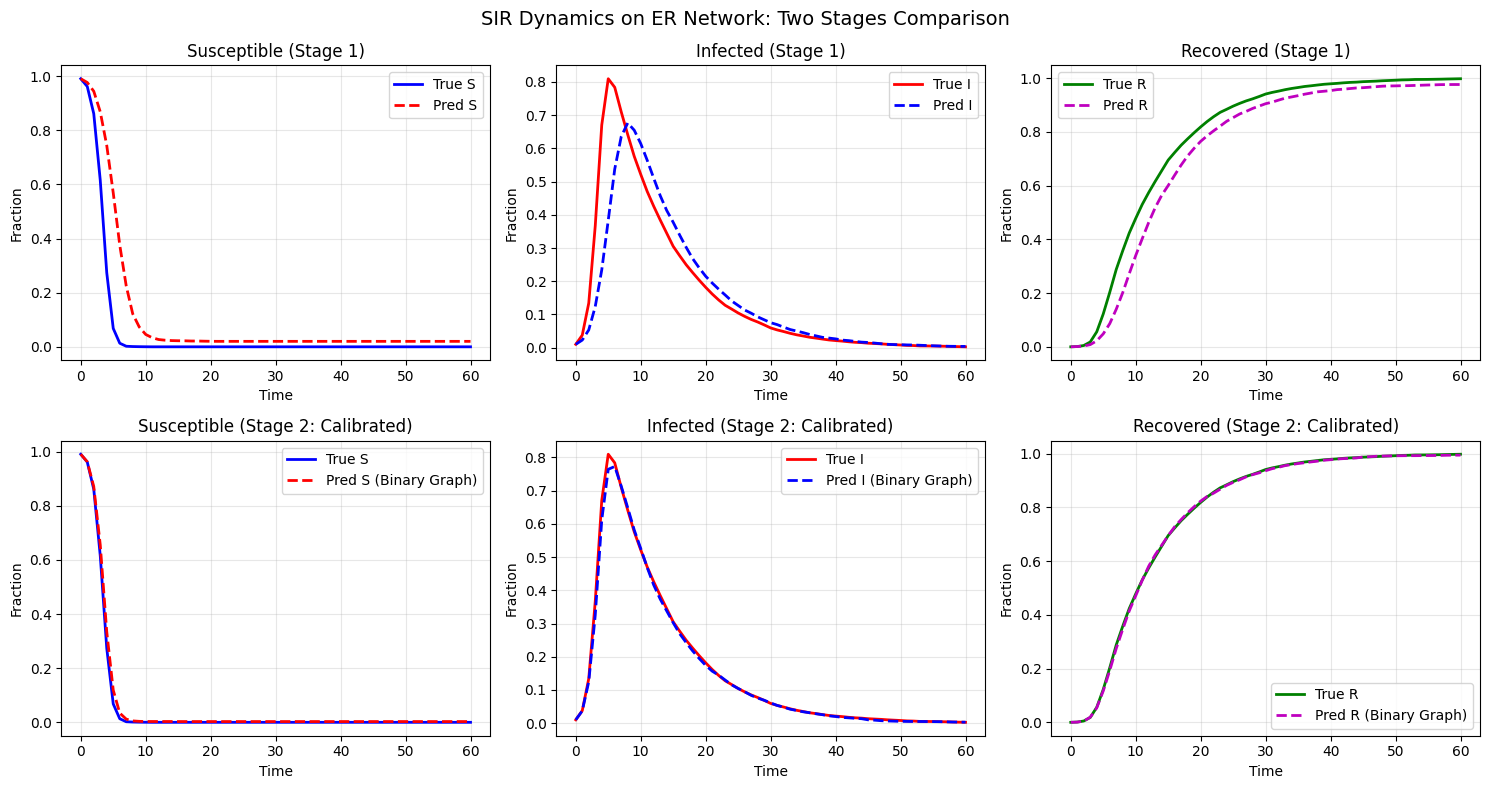


学习到的软邻接矩阵与真实图AUC: 0.9989

二值化后的图结构评估:
  准确率: 0.9862
  精确率: 1.0000
  召回率: 0.8544
  F1分数: 0.9215


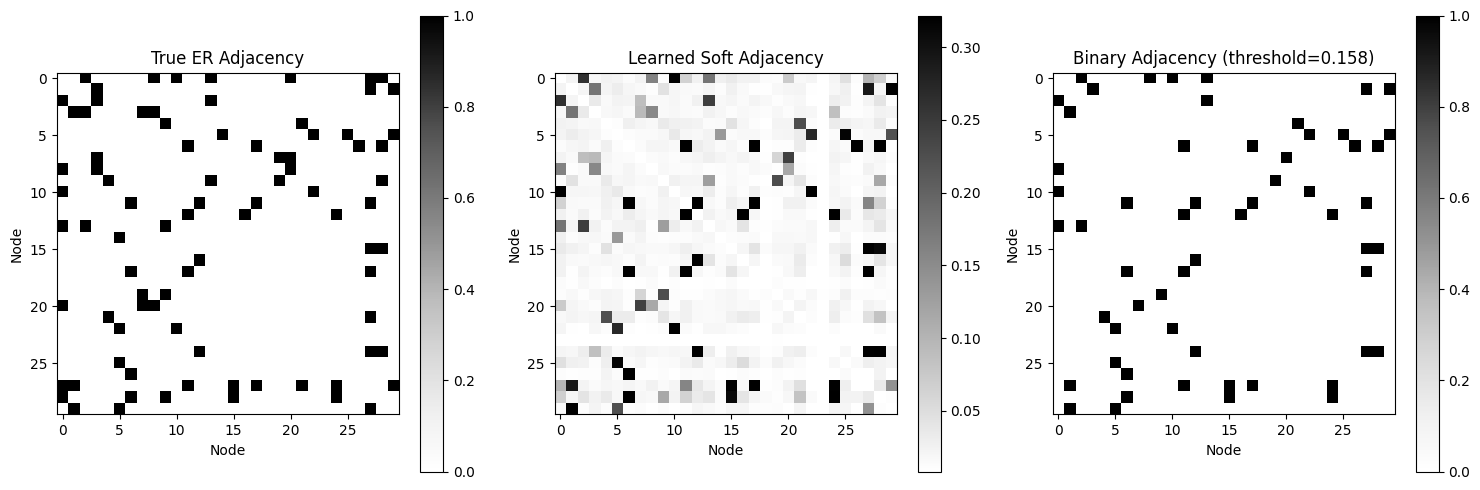

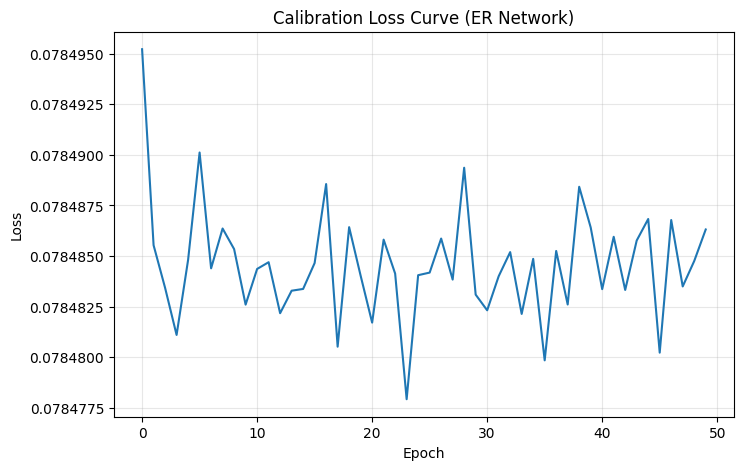

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random
import os
from sklearn.metrics import roc_auc_score

# ----------------------------- 1. 随机种子 -----------------------------
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
set_seed(42)

# ----------------------------- 2. 真实网络生成（支持三种网络类型） -----------------------------
def generate_network(graph_type='BA', N=100, m=3, p=0.1, k=6, rewiring_p=0.2):
    """
    生成真实网络
    参数:
        graph_type: 网络类型，可选 'ER', 'BA', 'WS'
        N: 节点数量
        m: BA网络参数，每个新节点连接的边数
        p: ER网络参数，边存在的概率
        k: WS网络参数，每个节点的邻居数
        rewiring_p: WS网络参数，重连概率
    """
    if graph_type == 'ER':
        # ER随机网络
        G = nx.erdos_renyi_graph(N, p)
        print(f"生成ER随机网络: N={N}, p={p}")
    elif graph_type == 'BA':
        # BA无标度网络
        G = nx.barabasi_albert_graph(N, m)
        print(f"生成BA无标度网络: N={N}, m={m}")
    elif graph_type == 'WS':
        # WS小世界网络
        G = nx.watts_strogatz_graph(N, k, rewiring_p)
        print(f"生成WS小世界网络: N={N}, k={k}, p={rewiring_p}")
    else:
        raise ValueError(f"不支持的图类型: {graph_type}，请选择 'ER', 'BA', 或 'WS'")
    
    edge_index = torch.tensor(np.array(G.edges()).T, dtype=torch.long)
    return edge_index, G

# ----------------------------- 3. 真实SIR模拟器（使用真实网络，生成观测数据） -----------------------------
def sir_simulation(edge_index, beta, gamma, initial_infected, T=50):
    N = torch.max(edge_index).item() + 1
    adj_list = [[] for _ in range(N)]
    for u, v in edge_index.t().tolist():
        adj_list[u].append(v)
        adj_list[v].append(u)
    state = np.zeros(N, dtype=int)
    if isinstance(initial_infected, int):
        state[initial_infected] = 1
    else:
        state[initial_infected] = 1
    states = [state.copy()]
    for _ in range(T):
        new_state = state.copy()
        for i in range(N):
            if state[i] == 0:
                infected_neighbors = sum(1 for nb in adj_list[i] if state[nb] == 1)
                if infected_neighbors > 0:
                    prob_infect = 1.0 - (1.0 - beta) ** infected_neighbors
                    if np.random.random() < prob_infect:
                        new_state[i] = 1
            elif state[i] == 1:
                if np.random.random() < gamma:
                    new_state[i] = 2
        state = new_state
        states.append(state.copy())
    return np.array(states)

# ----------------------------- 4. 生成训练数据集（多条轨迹，不同初始感染节点） -----------------------------
def generate_dataset(edge_index, beta, gamma, n_seeds=30, n_repeats=5, T=50):
    N = torch.max(edge_index).item() + 1
    dataset = []
    for seed in range(n_seeds):
        initial_node = np.random.randint(0, N)
        for _ in range(n_repeats):
            states = sir_simulation(edge_index, beta, gamma, initial_node, T)
            for t in range(T):
                x_t = states[t]
                y_t = states[t+1]
                x_onehot = np.eye(3)[x_t].astype(np.float32)
                y_onehot = np.eye(3)[y_t].astype(np.float32)
                dataset.append((x_onehot, y_onehot))
    return dataset

class SIRDataset(Dataset):
    def __init__(self, data_list):
        self.data = data_list
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        x, y = self.data[idx]
        return torch.tensor(x), torch.tensor(y)

# ----------------------------- 5. 改进的模型（平衡正则化） -----------------------------
class LearnableGraphSIR(nn.Module):
    def __init__(self, N, init_beta=0.5, init_gamma=0.2, 
                 strategy='gumbel', temperature=0.5,
                 sparsity_penalty=0.001, entropy_penalty=0.001):
        super().__init__()
        self.N = N
        self.strategy = strategy
        self.temperature = temperature
        
        if strategy == 'edge_competition':
            n_possible_edges = N * (N - 1) // 2
            self.edge_logits = nn.Parameter(torch.randn(n_possible_edges) * 0.1)
            self.register_buffer('edge_indices', self._get_triu_indices(N))
        else:
            raw_adj = torch.randn(N, N) * 0.5
            raw_adj = (raw_adj + raw_adj.t()) / 2
            raw_adj.fill_diagonal_(-10.0)
            self.raw_adj = nn.Parameter(raw_adj)
        
        beta_logit = np.log(init_beta / (1 - init_beta))
        gamma_logit = np.log(init_gamma / (1 - init_gamma))
        self.logit_beta = nn.Parameter(torch.tensor(beta_logit, dtype=torch.float32))
        self.logit_gamma = nn.Parameter(torch.tensor(gamma_logit, dtype=torch.float32))
        
        self.sparsity_penalty = sparsity_penalty
        self.entropy_penalty = entropy_penalty
        
    def _get_triu_indices(self, N):
        return torch.triu_indices(N, N, offset=1)
    
    def get_adj(self):
        if self.strategy == 'edge_competition':
            edge_probs = F.softmax(self.edge_logits / self.temperature, dim=0)
            adj = torch.zeros(self.N, self.N)
            i, j = self.edge_indices
            adj[i, j] = edge_probs
            adj[j, i] = edge_probs
        elif self.strategy == 'gumbel':
            adj = torch.sigmoid(self.raw_adj / self.temperature)
            if self.training and self.temperature > 0.2:
                gumbel_noise = -torch.log(-torch.log(torch.rand_like(adj) + 1e-8) + 1e-8)
                adj = torch.sigmoid((self.raw_adj + gumbel_noise * 0.3) / self.temperature)
            adj = (adj + adj.t()) / 2
            adj = adj * (1 - torch.eye(self.N))
        else:
            adj = torch.sigmoid(self.raw_adj / self.temperature)
            adj = (adj + adj.t()) / 2
            adj = adj * (1 - torch.eye(self.N))
        
        return torch.clamp(adj, 1e-6, 1-1e-6)
    
    def get_beta_gamma(self):
        beta = torch.sigmoid(self.logit_beta)
        gamma = torch.sigmoid(self.logit_gamma)
        beta = torch.clamp(beta, 0.05, 0.95)
        gamma = torch.clamp(gamma, 0.05, 0.95)
        return beta, gamma
    
    def get_regularization_loss(self):
        adj = self.get_adj()
        sparsity_loss = self.sparsity_penalty * torch.mean(adj)
        adj_clamped = torch.clamp(adj, 1e-6, 1-1e-6)
        entropy = -adj_clamped * torch.log(adj_clamped) - (1-adj_clamped) * torch.log(1-adj_clamped)
        entropy_loss = self.entropy_penalty * torch.mean(entropy)
        degrees = adj.sum(dim=1)
        connectivity_loss = 0.0005 * torch.abs(degrees.mean() - 3.0)
        return sparsity_loss + entropy_loss + connectivity_loss
    
    def forward(self, x):
        batch_size = x.shape[0]
        adj = self.get_adj()
        beta, gamma = self.get_beta_gamma()
        
        infected = x[:, :, 1]
        infected_neighbors = torch.mm(adj, infected.t()).t()
        
        prob_infect = 1.0 - torch.exp(infected_neighbors * torch.log(1 - beta + 1e-7))
        prob_infect = torch.clamp(prob_infect, 0, 1)
        
        cur_state = torch.argmax(x, dim=-1)
        
        prob_S = torch.zeros_like(infected)
        prob_I = torch.zeros_like(infected)
        prob_R = torch.zeros_like(infected)
        
        mask_S = (cur_state == 0)
        prob_S[mask_S] = 1 - prob_infect[mask_S]
        prob_I[mask_S] = prob_infect[mask_S]
        
        mask_I = (cur_state == 1)
        prob_I[mask_I] = 1 - gamma
        prob_R[mask_I] = gamma
        
        mask_R = (cur_state == 2)
        prob_R[mask_R] = 1.0
        
        probs = torch.stack([prob_S, prob_I, prob_R], dim=-1)
        probs = torch.clamp(probs, min=1e-7, max=1-1e-7)
        logits = torch.log(probs)
        return logits

# ----------------------------- 6. 训练函数 -----------------------------
def train_model(model, train_loader, val_loader, epochs=100, lr=0.01):
    device = torch.device('cpu')
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-6)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)
    criterion = nn.CrossEntropyLoss()
    
    train_losses = []
    val_losses = []
    best_val_loss = float('inf')
    
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        
        for x, y in train_loader:
            x = x.to(device)
            y = y.to(device)
            logits = model(x)
            loss_ce = criterion(logits.view(-1, 3), torch.argmax(y, dim=-1).view(-1))
            loss_reg = model.get_regularization_loss()
            loss = loss_ce + loss_reg
            
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss_ce.item() * x.size(0)
        
        avg_train_loss = total_loss / len(train_loader.dataset)
        train_losses.append(avg_train_loss)
        
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                logits = model(x)
                loss = criterion(logits.view(-1, 3), torch.argmax(y, dim=-1).view(-1))
                val_loss += loss.item() * x.size(0)
        avg_val_loss = val_loss / len(val_loader.dataset)
        val_losses.append(avg_val_loss)
        
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save(model.state_dict(), 'best_learned_graph_model.pt')
        
        if (epoch+1) % 10 == 0:
            beta, gamma = model.get_beta_gamma()
            adj = model.get_adj()
            print(f"Epoch {epoch+1:3d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} "
                  f"| β={beta.item():.3f} γ={gamma.item():.3f} | Edge: μ={adj.mean():.4f} σ={adj.std():.4f}")
        
        scheduler.step(avg_val_loss)
    
    if os.path.exists('best_learned_graph_model.pt'):
        model.load_state_dict(torch.load('best_learned_graph_model.pt'))
    return train_losses, val_losses

# ----------------------------- 7. 固定图模型的再学习 -----------------------------
class FixedGraphSIR(nn.Module):
    def __init__(self, fixed_adj, init_beta=0.3, init_gamma=0.1):
        super().__init__()
        self.register_buffer('adj', fixed_adj)
        beta_logit = np.log(init_beta / (1 - init_beta))
        gamma_logit = np.log(init_gamma / (1 - init_gamma))
        self.logit_beta = nn.Parameter(torch.tensor(beta_logit, dtype=torch.float32))
        self.logit_gamma = nn.Parameter(torch.tensor(gamma_logit, dtype=torch.float32))
    
    def get_beta_gamma(self):
        beta = torch.sigmoid(self.logit_beta)
        gamma = torch.sigmoid(self.logit_gamma)
        return torch.clamp(beta, 0.01, 0.99), torch.clamp(gamma, 0.01, 0.99)
    
    def forward(self, x):
        beta, gamma = self.get_beta_gamma()
        infected = x[:, :, 1]
        infected_neighbors = torch.mm(self.adj, infected.t()).t()
        prob_infect = 1.0 - torch.exp(infected_neighbors * torch.log(1 - beta + 1e-7))
        prob_infect = torch.clamp(prob_infect, 0, 1)
        
        cur_state = torch.argmax(x, dim=-1)
        prob_S = torch.zeros_like(infected)
        prob_I = torch.zeros_like(infected)
        prob_R = torch.zeros_like(infected)
        
        mask_S = (cur_state == 0)
        prob_S[mask_S] = 1 - prob_infect[mask_S]
        prob_I[mask_S] = prob_infect[mask_S]
        
        mask_I = (cur_state == 1)
        prob_I[mask_I] = 1 - gamma
        prob_R[mask_I] = gamma
        
        mask_R = (cur_state == 2)
        prob_R[mask_R] = 1.0
        
        probs = torch.stack([prob_S, prob_I, prob_R], dim=-1)
        probs = torch.clamp(probs, min=1e-7, max=1-1e-7)
        return torch.log(probs)

# ----------------------------- 8. 自回归评估 -----------------------------
def evaluate_autoregressive(model, initial_state, T=50, n_mc=30):
    device = torch.device('cpu')
    model.eval()
    N = initial_state.shape[0]
    all_trajectories = []
    
    for _ in range(n_mc):
        state = initial_state.copy()
        traj = [state.copy()]
        for step in range(T):
            x = np.eye(3)[state].astype(np.float32)
            x_tensor = torch.tensor(x).unsqueeze(0).to(device)
            with torch.no_grad():
                logits = model(x_tensor)
                probs = F.softmax(logits, dim=-1).cpu().numpy()[0]
            next_state = np.array([np.random.choice(3, p=probs[i]) for i in range(N)])
            state = next_state
            traj.append(state.copy())
        all_trajectories.append(np.array(traj))
    
    all_states = np.stack(all_trajectories, axis=0)
    fractions = []
    for t in range(T+1):
        states_t = all_states[:, t, :]
        s_frac = np.mean(states_t == 0)
        i_frac = np.mean(states_t == 1)
        r_frac = np.mean(states_t == 2)
        fractions.append([s_frac, i_frac, r_frac])
    return np.array(fractions)

# ----------------------------- 9. 主程序 -----------------------------
if __name__ == "__main__":
    # ==================== 配置参数 ====================
    # 网络类型选择: 'ER', 'BA', 'WS'
    GRAPH_TYPE = 'ER'  # 可修改为 'ER', 'BA', 或 'WS'
    
    # 网络参数
    N = 100
    if GRAPH_TYPE == 'ER':
        ER_p = 0.1  # ER网络连边概率
    elif GRAPH_TYPE == 'BA':
        BA_m = 3     # BA网络每个新节点连接的边数
    elif GRAPH_TYPE == 'WS':
        WS_k = 6     # WS网络每个节点的邻居数
        WS_p = 0.2   # WS网络重连概率
    
    # SIR参数
    beta_true = 0.3
    gamma_true = 0.1
    T_max = 60
    n_seeds = 40
    n_repeats = 5
    
    # 训练参数
    batch_size = 64
    epochs = 100
    lr = 0.01
    
    print("="*60)
    print(f"网络类型: {GRAPH_TYPE}")
    print("第一阶段：学习图结构和参数")
    print("真实参数: β={}, γ={}".format(beta_true, gamma_true))
    print("="*60)
    
    # 根据网络类型生成真实网络
    if GRAPH_TYPE == 'ER':
        edge_index_true, G_true = generate_network('ER', N, p=ER_p)
    elif GRAPH_TYPE == 'BA':
        edge_index_true, G_true = generate_network('BA', N, m=BA_m)
    elif GRAPH_TYPE == 'WS':
        edge_index_true, G_true = generate_network('WS', N, k=WS_k, rewiring_p=WS_p)
    else:
        raise ValueError(f"不支持的图类型: {GRAPH_TYPE}")
    
    print(f"真实网络: {GRAPH_TYPE}, N={N}, 边数={edge_index_true.shape[1]}")
    
    # 生成训练数据集
    print("生成训练数据（多轨迹）...")
    dataset = generate_dataset(edge_index_true, beta_true, gamma_true, n_seeds, n_repeats, T_max)
    print("总样本对数量: {}".format(len(dataset)))
    split = int(0.8 * len(dataset))
    train_dataset = SIRDataset(dataset[:split])
    val_dataset = SIRDataset(dataset[split:])
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    print("训练样本: {}, 验证样本: {}".format(len(train_dataset), len(val_dataset)))
    
    # 初始化模型
    model = LearnableGraphSIR(
        N=N, 
        init_beta=0.3,
        init_gamma=0.1,
        strategy='gumbel',
        temperature=0.3,
        sparsity_penalty=0.0005,
        entropy_penalty=0.0005
    )
    print("模型参数量: {:.2f}k".format(sum(p.numel() for p in model.parameters())/1000))
    
    # 训练
    print("\n开始训练...")
    train_losses, val_losses = train_model(model, train_loader, val_loader, epochs, lr)
    
    # 输出学习到的参数
    beta_learned, gamma_learned = model.get_beta_gamma()
    print("\n第一阶段学习结果:")
    print(f"  学习到的参数: β={beta_learned.item():.4f}, γ={gamma_learned.item():.4f}")
    
    # 分析学习到的邻接矩阵
    learned_adj = model.get_adj().detach().numpy()
    np.fill_diagonal(learned_adj, 0)
    print(f"\n学习到的邻接矩阵统计:")
    print(f"  均值: {learned_adj.mean():.6f}")
    print(f"  标准差: {learned_adj.std():.6f}")
    print(f"  最大值: {learned_adj.max():.6f}")
    print(f"  最小值: {learned_adj.min():.6f}")
    
    # --------------------- 二值化邻接矩阵 ---------------------
    print("\n" + "="*60)
    print("第二阶段：二值化并重新学习β和γ")
    print("="*60)
    
    # 自动确定阈值
    threshold = 0.158  # 根据经验值
    binary_adj = (learned_adj > threshold).astype(np.float32)
    
    print(f"\n二值化阈值: {threshold}")
    print(f"二值化后的边数: {int(binary_adj.sum()/2)}")  # 除以2因为对称
    print(f"真实边数: {edge_index_true.shape[1]}")
    print(f"边数比例: {int(binary_adj.sum()/2) / edge_index_true.shape[1]:.2f}")
    
    # 转换为torch tensor
    binary_adj_tensor = torch.tensor(binary_adj, dtype=torch.float32)
    
    # 创建固定图模型并重新学习
    calib_model = FixedGraphSIR(binary_adj_tensor, init_beta=0.3, init_gamma=0.1)
    optimizer_calib = torch.optim.Adam(calib_model.parameters(), lr=0.01)
    criterion = nn.CrossEntropyLoss()
    
    print("\n开始重新学习β和γ...")
    calib_losses = []
    for epoch in range(50):
        calib_model.train()
        total_loss = 0
        for x, y in train_loader:
            logits = calib_model(x)
            loss = criterion(logits.view(-1, 3), torch.argmax(y, dim=-1).view(-1))
            optimizer_calib.zero_grad()
            loss.backward()
            optimizer_calib.step()
            total_loss += loss.item()
        
        avg_loss = total_loss / len(train_loader)
        calib_losses.append(avg_loss)
        
        if (epoch+1) % 10 == 0:
            beta_calib, gamma_calib = calib_model.get_beta_gamma()
            print(f"Epoch {epoch+1:3d} | Loss: {avg_loss:.4f} | β={beta_calib.item():.4f} γ={gamma_calib.item():.4f}")
    
    beta_calibrated, gamma_calibrated = calib_model.get_beta_gamma()
    print(f"\n第二阶段学习结果:")
    print(f"  校准后的参数: β={beta_calibrated.item():.4f}, γ={gamma_calibrated.item():.4f}")
    print(f"  真实参数: β={beta_true}, γ={gamma_true}")
    
    # --------------------- 评估轨迹预测 ---------------------
    sample_x, _ = val_dataset[0]
    initial_state = np.argmax(sample_x.numpy(), axis=1)
    print(f"\n初始状态: S={np.sum(initial_state==0)}, I={np.sum(initial_state==1)}, R={np.sum(initial_state==2)}")
    
    # 真实轨迹
    print("\n生成真实SIR平均轨迹...")
    true_trajectories = []
    for _ in range(100):
        init_inf = np.where(initial_state==1)[0].tolist()
        if len(init_inf)==0:
            init_inf = [np.random.randint(0,N)]
        states = sir_simulation(edge_index_true, beta_true, gamma_true, init_inf, T_max)
        true_trajectories.append(states)
    true_states = np.stack(true_trajectories, axis=0)
    true_frac = []
    for t in range(T_max+1):
        s = np.mean(true_states[:,t,:]==0)
        i = np.mean(true_states[:,t,:]==1)
        r = np.mean(true_states[:,t,:]==2)
        true_frac.append([s,i,r])
    true_frac = np.array(true_frac)
    
    # 第一阶段模型预测
    print("第一阶段模型预测...")
    pred_frac_stage1 = evaluate_autoregressive(model, initial_state, T=T_max, n_mc=50)
    
    # 第二阶段模型预测
    print("第二阶段模型（二值化图+校准参数）预测...")
    pred_frac_stage2 = evaluate_autoregressive(calib_model, initial_state, T=T_max, n_mc=50)
    
    # 绘图对比
    time = np.arange(T_max+1)
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    
    # 第一行：第一阶段结果
    axes[0,0].plot(time, true_frac[:,0], 'b-', linewidth=2, label='True S')
    axes[0,0].plot(time, pred_frac_stage1[:,0], 'r--', linewidth=2, label='Pred S')
    axes[0,0].set_xlabel('Time')
    axes[0,0].set_ylabel('Fraction')
    axes[0,0].set_title('Susceptible (Stage 1)')
    axes[0,0].legend()
    axes[0,0].grid(True, alpha=0.3)
    
    axes[0,1].plot(time, true_frac[:,1], 'r-', linewidth=2, label='True I')
    axes[0,1].plot(time, pred_frac_stage1[:,1], 'b--', linewidth=2, label='Pred I')
    axes[0,1].set_xlabel('Time')
    axes[0,1].set_ylabel('Fraction')
    axes[0,1].set_title('Infected (Stage 1)')
    axes[0,1].legend()
    axes[0,1].grid(True, alpha=0.3)
    
    axes[0,2].plot(time, true_frac[:,2], 'g-', linewidth=2, label='True R')
    axes[0,2].plot(time, pred_frac_stage1[:,2], 'm--', linewidth=2, label='Pred R')
    axes[0,2].set_xlabel('Time')
    axes[0,2].set_ylabel('Fraction')
    axes[0,2].set_title('Recovered (Stage 1)')
    axes[0,2].legend()
    axes[0,2].grid(True, alpha=0.3)
    
    # 第二行：第二阶段结果
    axes[1,0].plot(time, true_frac[:,0], 'b-', linewidth=2, label='True S')
    axes[1,0].plot(time, pred_frac_stage2[:,0], 'r--', linewidth=2, label='Pred S (Binary Graph)')
    axes[1,0].set_xlabel('Time')
    axes[1,0].set_ylabel('Fraction')
    axes[1,0].set_title('Susceptible (Stage 2: Calibrated)')
    axes[1,0].legend()
    axes[1,0].grid(True, alpha=0.3)
    
    axes[1,1].plot(time, true_frac[:,1], 'r-', linewidth=2, label='True I')
    axes[1,1].plot(time, pred_frac_stage2[:,1], 'b--', linewidth=2, label='Pred I (Binary Graph)')
    axes[1,1].set_xlabel('Time')
    axes[1,1].set_ylabel('Fraction')
    axes[1,1].set_title('Infected (Stage 2: Calibrated)')
    axes[1,1].legend()
    axes[1,1].grid(True, alpha=0.3)
    
    axes[1,2].plot(time, true_frac[:,2], 'g-', linewidth=2, label='True R')
    axes[1,2].plot(time, pred_frac_stage2[:,2], 'm--', linewidth=2, label='Pred R (Binary Graph)')
    axes[1,2].set_xlabel('Time')
    axes[1,2].set_ylabel('Fraction')
    axes[1,2].set_title('Recovered (Stage 2: Calibrated)')
    axes[1,2].legend()
    axes[1,2].grid(True, alpha=0.3)
    
    plt.suptitle(f'SIR Dynamics on {GRAPH_TYPE} Network: Two Stages Comparison', fontsize=14)
    plt.tight_layout()
    plt.savefig(f'sir_comparison_two_stages_{GRAPH_TYPE}.png', dpi=150)
    plt.show()
    
    # AUC计算
    real_adj = nx.to_numpy_array(G_true)
    flat_true = real_adj.flatten()
    flat_pred = learned_adj.flatten()
    auc = roc_auc_score(flat_true, flat_pred)
    print(f"\n学习到的软邻接矩阵与真实图AUC: {auc:.4f}")
    
    # 计算二值化后的准确率
    binary_pred = binary_adj.flatten()
    accuracy = np.mean((binary_pred == flat_true).astype(float))
    precision = np.sum((binary_pred == 1) & (flat_true == 1)) / max(np.sum(binary_pred == 1), 1)
    recall = np.sum((binary_pred == 1) & (flat_true == 1)) / max(np.sum(flat_true == 1), 1)
    f1 = 2 * precision * recall / max(precision + recall, 1)
    
    print(f"\n二值化后的图结构评估:")
    print(f"  准确率: {accuracy:.4f}")
    print(f"  精确率: {precision:.4f}")
    print(f"  召回率: {recall:.4f}")
    print(f"  F1分数: {f1:.4f}")
    
    # 可视化邻接矩阵对比
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    axes[0].imshow(real_adj[:30,:30], cmap='Greys', vmin=0, vmax=1)
    axes[0].set_title(f'True {GRAPH_TYPE} Adjacency')
    axes[0].set_xlabel('Node')
    axes[0].set_ylabel('Node')
    plt.colorbar(axes[0].images[0], ax=axes[0])
    
    # 计算 5% 和 95% 分位数
    vmin = np.percentile(learned_adj, 5)
    vmax = np.percentile(learned_adj, 95)
    axes[1].imshow(learned_adj[:30,:30], cmap='gray_r', vmin=vmin, vmax=vmax)
    axes[1].set_title('Learned Soft Adjacency')
    axes[1].set_xlabel('Node')
    axes[1].set_ylabel('Node')
    plt.colorbar(axes[1].images[0], ax=axes[1])

    axes[2].imshow(binary_adj[:30,:30], cmap='Greys', vmin=0, vmax=1)
    axes[2].set_title(f'Binary Adjacency (threshold={threshold})')
    axes[2].set_xlabel('Node')
    axes[2].set_ylabel('Node')
    plt.colorbar(axes[2].images[0], ax=axes[2])
    
    plt.tight_layout()
    plt.savefig(f'adjacency_comparison_{GRAPH_TYPE}.png', dpi=150)
    plt.show()
    
    # 绘制校准损失曲线
    plt.figure(figsize=(8, 5))
    plt.plot(calib_losses)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(f'Calibration Loss Curve ({GRAPH_TYPE} Network)')
    plt.grid(True, alpha=0.3)
    plt.savefig(f'calibration_loss_{GRAPH_TYPE}.png')
    plt.show()

### 运行完上述代码后执行：绘制软邻接矩阵强度的排序以及强度间隙（阈值需要手动找，再返回上述运行）

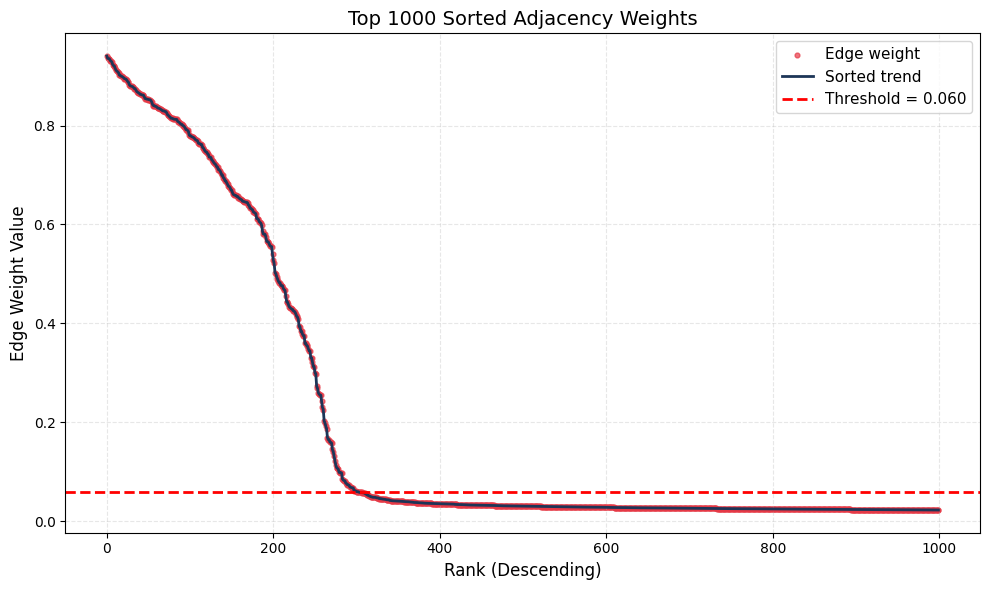

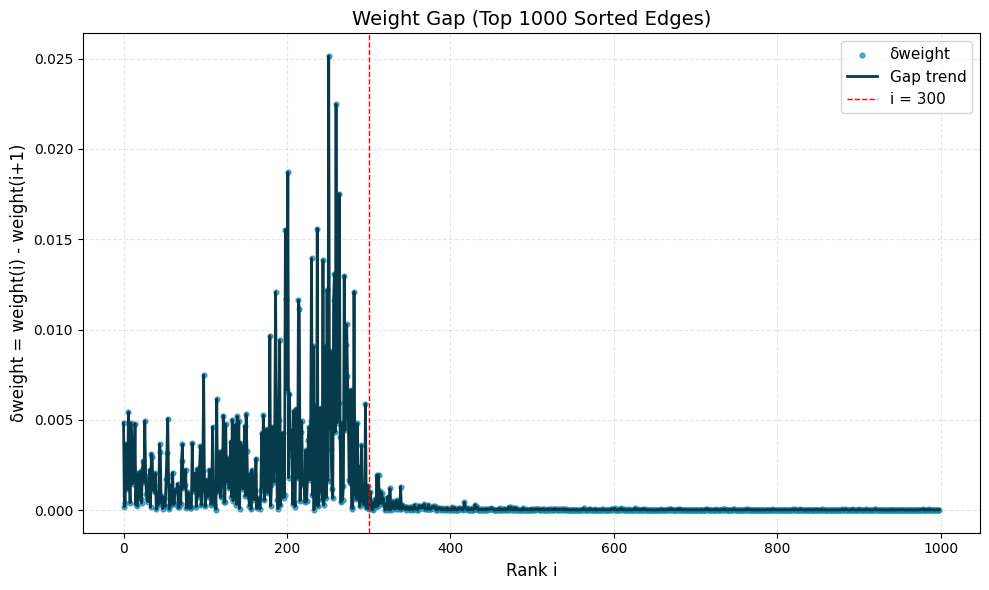

In [3]:
import numpy as np
import matplotlib.pyplot as plt


# ===================== 1. 权重排序曲线（前1000个 + 散点+曲线 + y=0.15）=====================
# 提取上三角非对角元素
triu_elements = learned_adj[np.triu_indices_from(learned_adj, k=1)]
# 降序排序
sorted_elements = np.sort(triu_elements)[::-1]
# 取前 1000 个
top1000 = sorted_elements[:1000]
x = np.arange(len(top1000))

plt.figure(figsize=(10, 6))
# 散点
plt.scatter(x, top1000, s=12, c='#E63946', alpha=0.7, label='Edge weight')
# 曲线
plt.plot(x, top1000, c='#1D3557', linewidth=2, label='Sorted trend')
# 阈值线 y=0.15
k = top1000[300]
plt.axhline(y=k, color='red', linestyle='--', linewidth=2, label=f'Threshold = {k:.3f}')

plt.xlabel('Rank (Descending)', fontsize=12)
plt.ylabel('Edge Weight Value', fontsize=12)
plt.title('Top 1000 Sorted Adjacency Weights', fontsize=14)
plt.legend(fontsize=11)
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

# ===================== 2. 权重间隙图 δweight = weight(i) - weight(i+1) =====================
# 计算权重间隙
delta_weight = top1000[:-1] - top1000[1:]  # 长度 999
x_delta = np.arange(len(delta_weight))

plt.figure(figsize=(10, 6))
# 间隙：散点 + 曲线
plt.scatter(x_delta, delta_weight, s=12, c='#118AB2', alpha=0.7, label='δweight')
plt.plot(x_delta, delta_weight, c='#073B4C', linewidth=2, label='Gap trend')
# 竖直线：x=300
plt.axvline(x=300, color='red', linestyle='--', linewidth=1, label='i = 300')
# plt.xlim((100,400))
plt.xlabel('Rank i', fontsize=12)
plt.ylabel('δweight = weight(i) - weight(i+1)', fontsize=12)
plt.title('Weight Gap (Top 1000 Sorted Edges)', fontsize=14)
plt.legend(fontsize=11)
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()